In [1]:
# Libraries
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from PIL import Image
import base64
from io import BytesIO
from typing import List, Optional
from scipy.stats import ttest_rel, shapiro
import torchvision.utils as vutils
import torch

# --- Custom packages ---
from compcats.datasets.fmri import nsd
from compcats.datasets.fmri.utils import nsd_ds_utils
from compcats.localizer import localizer
from compcats.utils import model_utils, coco_utils, responsecomparison_utils as rc_utils
import main_analysis as ma
import paths

# Paths
RESULTS_DIR = 'results/exploration/explore_interpret'
MODELS_DIR = 'models'
PLOTS_DIR = f'{RESULTS_DIR}/plots/'
os.makedirs(PLOTS_DIR, exist_ok=True)
NSD_DIR = paths.NSD_DIR
GRILLSPECTOR_LOCALIZER_DIR = paths.GRILLSPECTOR_LOCALIZER_DIR
COCO_ANNOTATIONS_PATH = paths.COCO_ANNOTATIONS_PATH

# Plot settings
import matplotlib as mpl
from matplotlib import rcParams
rcParams.update({'figure.autolayout': False})
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42
mpl.rcParams['font.family'] = 'Avenir'

# Generate Data

## Subject data

In [ ]:
# Data utils

TTHRESHOLD = 7
FROIS = ['FFA', 'PPA', 'EBA']
SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]  # NSD subjects
MODEL_LOCALIZER = 'grillspector'
MODEL_LOCALIZER_DIR = GRILLSPECTOR_LOCALIZER_DIR
SHARED1000_NSDIDS = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

TOP_MODELS = [
    'vitb16siglip2res224',
    'resnet50openaiclip',
    # 'convnexttinyimagenet1kv1',
    # 'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    # 'resnet101imagenet1kv1',
    'vitb14dinov2'
]

SUBJECTS_DATA = {}
MODELS_DATA = {}

# Stimuli
STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli
# Subjects data
for froi in FROIS:
    for subject in SUBJECTS:
        subject_data, images_df = nsd.get_betas(
            NSD_DIR, subject, froi, TTHRESHOLD, subset=None, voxels=True
        )
        # Add info to images_df
        images_df = coco_utils.add_image_info_to_df(images_df, COCO_ANNOTATIONS_PATH)
        subject_data = subject_data[~images_df['nsdId'].isin(SHARED1000_NSDIDS)]
        images_df = images_df[~images_df['nsdId'].isin(SHARED1000_NSDIDS)].reset_index(drop=True)
        SUBJECTS_DATA[(subject, froi)] = {
            'subject_data': subject_data,
            'images_df': images_df
        }
        print(f"Loaded subject {subject}, {froi}, data shape: {subject_data.shape}, images_df shape: {images_df.shape}")

def get_model_data(model_name, froi):
    if (model_name, froi) in MODELS_DATA:
        return MODELS_DATA[(model_name, froi)]
    else:
        print(f"Loading model data for {model_name}, {froi}...")
        # Get model and layer
        model = ma.get_model(model_name)
        layer = ma.get_froi_models_layers(froi, froi)[model_name]
        model_data = model_utils.get_dataset_activations(
                MODELS_DIR, NSD_DIR, model, layer, 'nsd', froi, TTHRESHOLD, subset=None,
                froi_localizer=MODEL_LOCALIZER, froi_localizer_dir=MODEL_LOCALIZER_DIR, device='cpu'
            )
        MODELS_DATA[(model_name, froi)] = model_data
        return model_data

def get_data(
    subject: int,
    froi: str,
    subset: int | None, # 515 for shared, None for subject-specific set
    model_name: str,
    nsdids: Optional[List[int]] = None
):
    assert subset is None, "Only support subset=None (subject-specific) for now"
    # Subject data
    subject_data = SUBJECTS_DATA[(subject, froi)]['subject_data']
    images_df = SUBJECTS_DATA[(subject, froi)]['images_df']
    # Model data
    stimuli = STIMULI
    model_data = get_model_data(model_name, froi)
    # Choose subject-specific images if needed
    if subset is None:
        subject_nsdids = images_df['nsdId'].values
        stimuli = stimuli[subject_nsdids]
        model_data = model_data[subject_nsdids]

    # Get correlations for validation
    pearsonr = rc_utils.pearsonr(
        subject_data.mean(axis=-1), model_data.mean(axis=-1)
    )
    rdmr = rc_utils.rdmr(subject_data, model_data)
    print(f"Full subset, \nMean Pearson r: {pearsonr:.4f}, RDMR: {rdmr:.4f}")

    # Store Voxel/Unit-averaged responses
    subject_data_mean = subject_data.mean(axis=-1).cpu().numpy()
    model_data_mean = model_data.mean(axis=-1).cpu().numpy()
    ## Also store z-scored versions
    subject_data_mean_zscored = (subject_data_mean - subject_data_mean.mean()) / subject_data_mean.std()
    model_data_mean_zscored = (model_data_mean - model_data_mean.mean()) / model_data_mean.std()

    if nsdids is not None:
        subject_data_mean_nsdid_subset = subject_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_nsdid_subset = model_data_mean[np.isin(images_df['nsdId'].values, nsdids)]
        subject_data_mean_zscored_nsdid_subset = subject_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        model_data_mean_zscored_nsdid_subset = model_data_mean_zscored[np.isin(images_df['nsdId'].values, nsdids)]
        # Get correlations for validation
        pearsonr_mean = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_nsdid_subset),
            torch.tensor(model_data_mean_nsdid_subset)
        )
        pearsonr_mean_zscored = rc_utils.pearsonr(
            torch.tensor(subject_data_mean_zscored_nsdid_subset), 
            torch.tensor(model_data_mean_zscored_nsdid_subset)
        )
        print(f"nsd ID subset mean, \nMean Pearson r: {pearsonr_mean:.4f}, Z-scored Pearson r: {pearsonr_mean_zscored:.4f}")

        subject_data_mean_zscored = subject_data_mean_zscored_nsdid_subset
        model_data_mean_zscored = model_data_mean_zscored_nsdid_subset

        nsdid_indices = np.isin(images_df['nsdId'].values, nsdids)
        subject_data = subject_data[nsdid_indices]
        stimuli = stimuli[nsdid_indices]
        model_data = model_data[nsdid_indices]
        images_df = images_df[nsdid_indices].reset_index(drop=True)

    mean_responses_df = pd.DataFrame({
        'idx': images_df.index,
        'nsd_image_id': images_df['nsdId'],
        'subject_response': subject_data_mean_zscored,
        'model_response': model_data_mean_zscored,
        'response_diff': subject_data_mean_zscored - model_data_mean_zscored,
        'labels': images_df['labels'],
    })
    return mean_responses_df, images_df, stimuli, subject_data, model_data

In [ ]:
# Make a big csv of all mean z-scored responses

mean_zscored_responses_df_path = f'{RESULTS_DIR}/subject_specific_mean_zscored_responses.csv'

STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

FROIS = ['FFA', 'PPA', 'EBA']
SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'{RESULTS_DIR}/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

# MODEL_NAMES = [
#     'alexnetimagenet1kv1',
#     'alexnetipclref01',
#     # 'alexnetbarlowtwins',
#     # 'vgg16imagenet1kv1',
#     'resnet18imagenet1kv1',
#     # 'resnet18tdannsupervisedlw10',
#     # 'resnet18tdannsimclrlw1',
#     'resnet50imagenet1kv2',
#     'resnet50openaiclip',
#     # 'resnet50simclr',
#     # 'resnet50robustl2eps3',
#     'resnet50sin',
#     'resnet50ecoset',
#     'resnet50faceobfuscation',
#     # 'resnet50toponettau30',
#     'resnet50cesslbarlowtop',
#     'resnet50blurstrong',
#     # 'resnet101imagenet1kv1',
#     # 'resnet101openaiclip',
#     # 'bagnet33', # TODO: Optimize RAM
#     # 'cornets',
#     # 'cornetz',
#     # 'convnexttinyimagenet1kv1',
#     # 'vitb32imagenet1kv1',
#     # 'vitb32openaiclip',
#     # 'vitb32dreamsimopenclip',
#     # 'vitb16imagenet21k',
#     # 'vitb16openaiclip',
#     'vitb16siglip2res224',
#     # 'vitb16eva028bs8bb131k',
#     'vitb16synclr',
#     # 'vitb14dinov2',
#     # 'vitb14dinov2reg',
#     # 'vitl14openaiclip',
#     # 'vitl14kosmos2'
# ]

# TODO: Load csv first if exists
dfs = []

for froi in FROIS:
    for subject in SUBJECTS:
        subject_response_mean = SUBJECTS_DATA[(subject, froi)]['subject_data'].mean(axis=-1).cpu().numpy()
        subject_response_mean_zscored = (subject_response_mean - subject_response_mean.mean()) / subject_response_mean.std()
        froi_subject_df = pd.DataFrame({
            'idx_local': np.arange(len(subject_response_mean_zscored)),
            'nsd_id': SUBJECTS_DATA[(subject, froi)]['images_df']['nsdId'],
            'froi': froi,
            'subject': subject,
            'subject_response': subject_response_mean_zscored,
        })
        dfs.append(froi_subject_df)
        # mean_response_df = pd.concat([mean_response_df, froi_subject_df], axis=0, ignore_index=True)
dfs = pd.concat(dfs, axis=0, ignore_index=True)

MODEL_NAMES = ma.get_model_names()
for froi in FROIS:
    for model_name in ['resnet50imagenet1kv2']:
        model_data = get_model_data(model_name, froi)
        for subject in SUBJECTS:
            mask = (dfs["subject"] == subject) & (dfs["froi"] == froi)
            nsdids = dfs[mask]['nsd_id'].values
            model_data_sbj = model_data[nsdids]
            model_response_mean = model_data_sbj.mean(axis=-1).cpu().numpy()
            model_response_mean_zscored = (model_response_mean - model_response_mean.mean()) / model_response_mean.std()
            dfs.loc[mask, f'{model_name}_response'] = model_response_mean_zscored
            dfs.to_csv(mean_zscored_responses_df_path, index=False)
        print(f"Done {model_name}, {froi}")
display(dfs)

Done resnet50imagenet1kv2, FFA
Done resnet50imagenet1kv2, PPA
Done resnet50imagenet1kv2, EBA


,idx_local,nsd_id,froi,subject,subject_response,resnet50imagenet1kv2_response
0,0,13,FFA,1,-1.339636,-0.756681
1,1,27,FFA,1,-0.748274,-0.326486
2,2,71,FFA,1,-1.464531,-0.587275
3,3,85,FFA,1,-0.524146,-0.675945
4,4,88,FFA,1,-0.275195,-0.431272
...,...,...,...,...,...,...
208693,8297,72969,EBA,8,-0.355957,2.479908
208694,8298,72980,EBA,8,-1.404375,-0.104512
208695,8299,72991,EBA,8,-0.872240,-1.538212
208696,8300,72995,EBA,8,-0.746166,-1.890897


## Add other models

In [4]:
TOP_MODEL_NAMES = [
    # 'vitb16siglip2res224',
    'resnet50openaiclip',
    # 'convnexttinyimagenet1kv1',
    # 'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    # 'resnet101imagenet1kv1',
    'vitb14dinov2'
]
for model_name in TOP_MODEL_NAMES:
    print(model_name)
    for froi in ['FFA', 'PPA', 'EBA']:
        print(ma.get_froi_models_layers(froi, froi)[model_name])
    print()

resnet50openaiclip
layer4.1.relu1
layer4.2.relu3
layer4.0.bn3

vitb14dinov2reg
blocks.8.attn
blocks.7.mlp
blocks.9.norm2

resnet50simclr
avgpool
layer3.5.conv1
avgpool

resnet50toponettau30
layer4.1.relu3
avgpool
avgpool

cornets
V4.nonlin2
V4.norm1_3
IT.norm3_0

vitb14dinov2
blocks.11.norm2
blocks.10.norm2
blocks.11.attn



In [ ]:
# STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

TTHRESHOLD = 7
FROIS = ['FFA', 'PPA', 'EBA']
SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]  # NSD subjects
MODEL_LOCALIZER = 'grillspector'
MODEL_LOCALIZER_DIR = GRILLSPECTOR_LOCALIZER_DIR
mean_zscored_responses_df_path = f'{RESULTS_DIR}/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

TOP_MODEL_NAMES = [
    # 'vitb16siglip2res224',
    'resnet50openaiclip',
    # 'convnexttinyimagenet1kv1',
    # 'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    # 'resnet101imagenet1kv1',
    'vitb14dinov2'
]

for model_name in TOP_MODEL_NAMES:
    if model_name in resp_df.columns:
        # Check the length of the column, if it's the same as resp_df length, skip
        if len(resp_df[model_name]) == len(resp_df):
            print(f"Model {model_name} already in dataframe, skipping...")
            continue
    model = ma.get_model(model_name)
    layers = []
    for froi in FROIS:
        layer = ma.get_froi_models_layers(froi, froi)[model_name]
        layers.append(layer)
    layers = list(set(layers))
    model_data = model_utils.get_dataset_activations(
            MODELS_DIR, NSD_DIR, model, layers, 'nsd', subset=None, device='cpu'
        )
    if len(layers) == 1:
        print("Only one layer, wrapping in dict")
        model_data = {layers[0]: model_data}
    breakpoint()
    for froi in FROIS:
        froi_layer = ma.get_froi_models_layers(froi, froi)[model_name]
        model_froi_mask = localizer.get_froi_mask(
            MODEL_LOCALIZER_DIR, MODEL_LOCALIZER, MODELS_DIR, ma.get_model(model_name),
            froi_layer, froi, TTHRESHOLD, device='cpu'
        )
        model_froi_data = model_data[froi_layer][..., model_froi_mask].cpu().numpy()
        for subject in SUBJECTS:
            print(f"Processing model {model_name}, {froi}, subject {subject}...")
            mask = (resp_df["subject"] == subject) & (resp_df["froi"] == froi)
            nsdids = resp_df[mask]['nsd_id'].values
            model_data_sbj = model_froi_data[nsdids]
            model_response_mean = model_data_sbj.mean(axis=-1)
            model_response_mean_zscored = (model_response_mean - model_response_mean.mean()) / model_response_mean.std()
            resp_df.loc[mask, f'{model_name}_response'] = model_response_mean_zscored
            resp_df.to_csv(mean_zscored_responses_df_path, index=False)
            print(f"Done {model_name}, {froi}, subject {subject}")
    print(f"Done {model_name}")

Processing model resnet50openaiclip, FFA, subject 1...
Done resnet50openaiclip, FFA, subject 1
Processing model resnet50openaiclip, FFA, subject 2...
Done resnet50openaiclip, FFA, subject 2
Processing model resnet50openaiclip, FFA, subject 3...
Done resnet50openaiclip, FFA, subject 3
Processing model resnet50openaiclip, FFA, subject 4...
Done resnet50openaiclip, FFA, subject 4
Processing model resnet50openaiclip, FFA, subject 5...
Done resnet50openaiclip, FFA, subject 5
Processing model resnet50openaiclip, FFA, subject 6...
Done resnet50openaiclip, FFA, subject 6
Processing model resnet50openaiclip, FFA, subject 7...
Done resnet50openaiclip, FFA, subject 7
Processing model resnet50openaiclip, FFA, subject 8...
Done resnet50openaiclip, FFA, subject 8
Processing model resnet50openaiclip, PPA, subject 1...
Done resnet50openaiclip, PPA, subject 1
Processing model resnet50openaiclip, PPA, subject 2...
Done resnet50openaiclip, PPA, subject 2
Processing model resnet50openaiclip, PPA, subject 

Using cache found in /home/alishd/.cache/torch/hub/facebookresearch_dinov2_main
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:43: UserWarning: xFormers is available (SwiGLU)
  warnings.warn("xFormers is available (SwiGLU)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:27: UserWarning: xFormers is available (Attention)
  warnings.warn("xFormers is available (Attention)")
/home/alishd/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:33: UserWarning: xFormers is available (Block)
  warnings.warn("xFormers is available (Block)")


# Image Sets

In [64]:
bags = {
    1: { # ~5000?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1162, 1487, 2429, 2795, 3532, 4221, 4719, 5156, 6137, 6315,
                    8213, 8486, 8489, 8757, 8858, 10319, 11431, 12460, 15180,
                    15555, 17505, 18569, 19079, 21064, 21723, 23796, 25131
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    1136, 1346, 2125, 7627, 8743, 12013, 12258, 14631, 15835, 16649,
                    18170, 19301, 19471, 21193, 21375
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1512, 3644, 6653, 6452, 8503, 10831, 9774, 11936, 11668, 12225, 12469,
                    18011, 15718, 16846, 14841, 16678, 14738, 23613, 22133, 20263, 27144,
                    20545, 23538, 22828, 28138, 20541, 28690, 31280, 36557, 33495, 37128, 
                    43345, 41563, 40001, 37621, 51914, 52447, 48202, 47272, 51008,
                    49530, 57460, 59576, 65647, 71502
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    103, 104, 15240, 15536, 19736, 11611, 6793, 21755, 4685, 1378,
                    13106, 11949, 9452, 14883, 20034, 13377, 20049, 5683, 12490, 6022, 25368,
                    13299, 6555, 12010, 31106, 46990, 43162, 31415, 34318, 52060, 34030,
                    50981, 42749, 49170, 35049, 47918, 37954, 57114, 72710,
                    65005, 54552, 63396, 53402, 67649, 68896
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    222, 3016, 3803, 5237, 7354, 7355, 7360, 8910,
                    10227, 10929, 11376, 11618, 18312, 19592,
                    20171, 21069, 21394, 22531, 23018
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1309, 452, 513, 1510, 2655, 13439, 13632, 20243, 20308, 20397, 20493
                ],
            }
        }
    },
    2: { # # ~6800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    # 28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    # 36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 890, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749,
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 18958, 21222, 21580, 22557, 28555,
                    28569, 28934, 28837, 30503, 30934, 32235, 32439, 33666, 34158, 34772,
                    36255, 44755, 45183, 45927, 48741, 50662, 51666, 56027
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    5, 333, 430, 743, 890, 2473, 2943, 3928, 4155, 4741, 5005, 5082, 6837, 8749,
                    9417, 9429, 10376, 10963, 12343, 13469, 13867, 14798, 15663, 16602, 16504, 
                    17312, 18455, 22161, 22481, 23007
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': { # ~8500
                'label': 'Human Faces',
                'nsdids': [
                    836, 1209, 7642, 7681, 16991, 18030, 21222, 22557, # 18958 21580
                    28934, 28837, 30934, 32235, 32439, 33666, 34158, # 28555, 28569, 30503
                    34772, 45183, 45927, 56027, # 36255 44755 48741, 50662, 51666
                    56373, 60189, 62821, 65027, 66244, 
                    71320, 68181, 66244, 65027, 62821, 60189, 56373 
                ], 
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    26050, 26860, 27682, 27824, 30316, 30577, 33486
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    44, 1163, 2665, 3684, 9363, 13578, 17070, 17146, 23628, 25482, 26640, 27637,
                    28387, 29961, 31413, 32166, 32837, 33769, 35316, 35352, 35641, 38705, 40208,
                    40908, 42107, 42622, 43957, 44326, 44595, 47713
                ],
            }
        },
        'bodies_covered': {
            'bag1': {
                'label': 'Typical Bodies',
                'nsdids': [
                    # 437, 1716, 2379, 3337, 4958, 7756, 9871, 9686, 10161, 13337, 14080, 14522,
                    # 15057, 15563, 16028, 16493, 17447, 18520, 20083, 20974, 22259, 24310, 26031,
                    # 26050, 26860, 27682, 27824, 30316, 30577, 33486
                    0
                ],
            },
            'bag2': {
                'label': 'Covered Bodies',
                'nsdids': [
                    # 1125, 2048, 2170, 2983, 3213, 4105, 4114, 4120,
                    # 4130, 4140, 4141, 4142, 4143, 4144, 4145,
                    # 4146, 4147, 4148
                    0
                ],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    89, 229, 4727, 5176, 5659, 72704, 72382, 71576, 71472, 70287, 
                    5854, 6767, 12617, 12671, 14331, 15091, 64993, 63853, 59358, 
                    16080, 17168, 17573, 18481, 62389, 61267, 58095, 57782, 56632, 55650, 
                    53825, 53261, 49978, 49920, 
                ],
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses', #14, 20, 22, 23
                'nsdids': [
                    696, 3961, 5888, 72608, 70797, 70036, 68898, 64587, 63352, 61203,
                    61189, 59841, 58459, 54756, 53447, 50701, 48593, 45395, 45291, 37809,
                    34740, 32339, 19704, 16287, 15378, 13024, 11248, 6671, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717, 15478,
                    16906, 17187, 17277, 17328, 18701, 18815, 21472, 22663, 24589, 24661, 26049,
                    28124, 29193, 31024, 31227, 31658, 32393, 32495, 34930, 35055, 35570,
                    37251, 37293, 38179, 39214, 39431, 40442, 41713, 41772, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    645, 1085, 1219, 1518, 1777, 1908, 3683, 4237,
                    4534, 5221, 5387, 6492, 7012, 11163, 11828, 13050, 13162, 13810, 14435, 15994,
                    17282, 17803, 19084, 21991, 23503, 25888, 31486, 32927, 36245, 36678, 37975,
                    39799, 39881, 42526, 43576, 44489, 44488, 45032, 5637
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717,
                    15478, 16906, 17187, 17277, 17328, 18701, 24589, 24661, 26049, 28124, # 18815, 21472, 22663,
                    29193, 31658, 32393, 32495, 35055, 35570, 37251, # 31024, 31227, 34930
                    37293, 38179, 39214, 41713, 41772 #  39431, 40442, 2480, 3099,
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    1085, 1219, 1908, 5221, # 645 1518, 1777 3683, 4237, 4534
                    5387, 6492, 7012, 11163, 11828, 13162, 13810, 15994, # 13050 14435
                    17282, 17803, 19084, 21991, 31486, 32927,  # 23503, 25888 36245, 36678,
                    37975, 39799, 42526, 43576, 44489, 44488, 45032, 5637 # 39881
                ],
            }
        },
        'scenes_localizerlike' : {
            'bag1': {
                'label': 'Localizer-like Scenes',
                'nsdids': [
                    4414, 10676, 12988, 14717, 24661, 28124, 35055, 35570, 1219, 4534, 5387,
                    13050, 14435, 31486, 23503, 25888, 36245, 36678, 37975, 44489, 1268,
                    5387, 5778, 6287, 6755, 6719, 7805, 10288, 11294, 12744, 13906, 
                    15317, 17133, 18883,  
                ],
                'all_previous_candidate': [
                    150, 328, 1317, 4050, 4414, 5716, 10676, 12988, 14486, 14717,
                    15478, 16906, 17187, 17277, 17328, 18701, 24589, 24661, 26049, 28124,
                    18815, 21472, 22663, 29193, 31658, 32393, 32495, 35055, 35570, 37251,
                    31024, 31227, 34930, 37293, 38179, 39214, 41713, 41772, 39431, 40442,
                    2480, 3099, 1085, 1219, 1908, 5221, 645, 1518, 1777, 3683,
                    4237, 4534, 5387, 6492, 7012, 11163, 11828, 13162, 13810, 15994,
                    13050, 14435, 17282, 17803, 19084, 21991, 31486, 32927, 23503, 25888,
                    36245, 36678, 37975, 39799, 42526, 43576, 44489, 44488, 45032, 5637,
                    39881
                ],
                'liberal': [
                    4414, 10676, 12988, 14717, 24661, 28124, 35055, 35570, 1219, 4534, 5387,
                    13050, 14435, 31486, 23503, 25888, 36245, 36678, 37975, 44489
                ],
                'conservative': [
                    12988, 24661, 35570, 4534, 5387, 13050, 14435, 31486, 23503, 25888, 
                    36245, 36678, 37975, 44489,
                ]
            },
            'bag2': {
                'label': 'Non-localizer-like Scenes',
                'nsdids': [
                    18815, 40442, 3099, 1301, 1476, 1916, 2034, 2144, 3160, 4226, 
                    4461, 4699, 5666, 6104, 7271, 7442, 7961, 10853, 11229, 
                    16699, 16679, 17798, 20995, 23609, 25102, 25110, 26777, 26881, 
                ],
            }
        },
        'scenes_animates': {
            'bag1': { # localizer-like scenes without animate objects
                'label': 'Without animates',
                'nsdids': [
                    4414, 10676, 12988, 14717, 24661, 28124, 35055, 35570, 1219, 4534, 5387,
                    13050, 14435, 31486, 23503, 25888, 36245, 36678, 37975, 44489, 1268,
                    5387, 5778, 6287, 6755, 6719, 7805, 10288, 11294, 12744, 13906, 
                    15317, 17133, 18883,
                ],
            },
            'bag2': { # non-localizer-like scenes with animate objects
                'label': 'With animates',
                'nsdids': [
                    80, 229, 310, 836, 1806, 1997, 2697, 2902, 4421, 4617, 
                    4836, 4818, 5666, 6177, 7036, 7887, 8800, 11255, 11344, 12552, 
                    14075, 14879, 16437, 17089, 17168, 19392, 19826, 20126, 23059, 23658
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    18815, 40442, 3099, 1301, 1476, 2034, 2144, 3160, 4226, 4699, 
                    6104, 70417, 7961, 10853, 11229, 16699, 16679, 23609, 25110, 70743, 
                    67206, 65626, 72953, 71169, 58032, 58018, 56079, 56044, 51858, 48409, 
                    48335, 45147, 44500
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    80, 229, 310, 836, 1806, 1997, 2697, 2902, 4421, 4617, 
                    4836, 4818, 5666, 6177, 7036, 7887, 8800, 11255, 11344, 12552, 
                    14075, 14879, 16437, 17098, 17168, 19392, 19826, 20126, 23059, 23658
                ],
            }
        },
    },
    3: { # ~5000
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    41765, 42609, 45625, 46581, 8004
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    109, 625, 1879, 3947, 4932, 6794, 7197, 7340, 7463, 7542, 7823, 9221, 9938,
                    11810, 12230, 12758, 16719, 18889, 21717, 23513, 27334, 28482, 29701, 32719,
                    37762, 43980
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 129, 287, 7807, 8272, 8811, 9023, 11291, 11912, 13494, 14153, 14189, 16329,
                    # 18279, 19893, 21525, 25264, 28820, 32055, 33274, 33480, 4633, 41421,
                    # 41765, 42609, 45625, 46581, 8004
                    129, 287, 7807, 8272, 11912, 13494, 14153, # 8811, 9023, 11291
                    14189, 16329, 18279, 19893, 21525, 25264, 33274, 33480, # 32055 28820 4633
                    41421, 41765, 42609, # 45625, # 46581, # , 8004 # 
                    69127, 67185, 66970, 66476, # 64692, 
                    72186, 69810, 64696, 63139, 62880
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1045, 1397, 2262, 3568, 5864, 6650, 7338, 10644, 13690, 13794, 13804,
                    16357, 17793, 21374, 22770, 25027, 25911, 32797, 32964, 34159,
                    39313, 41204, 56009, 47058
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    590, 705, 1847, 2043, 2230, 3101, 3218, 5662, 6931, 7702, 8060, 8099, 10439,
                    11138, 11152, 11284, 11401, 11739, 12124, 15305, 17931, 19948, 20000,
                    21837, 25688
                ],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    700, 1032, 1103, 1543, 1921, 2262, 2804, 3568, 3933, 4314, 
                    4684, 5198, 10644, 12500, 12968, 13405, 13554, 
                    13731, 14166, 16266, 16236, 17869, 18058, 19734, 20460, 20968, 22050, 
                    22190, 22770, 23021, 
                ],
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    2594, 2592, 3221, 3262, 3924, 72972, 72026, 70834, 70369, 
                    4013, 6209, 7420, 13592, 14254, 14358, 69360, 69102, 59743, 58498,
                    18162, 21372, 21938, 24606, 24831, 32952, 57608, 50388, 50077, 
                    47739, 46715, 46555, 44180, 32952, 
                    # 666, 2059, 1990, 3148, 5043, 5681, 7380, 14595,
                    # 14774, 19508 23372
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    11, 406, 515, 1179, 1255, 2133, 2496, 2463, 2937, 3091,
                    3396, 3758, 5014, 7632, 8294, 8904, 8911, 8989, 9852, 10236,
                    11346, 12054, 12583, 12978, 13642, 15569, 19269, 20624, 22882
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    1239, 1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, 11195, 12018,
                    12649, 14272, 14816, 17467, 17615, 18643, 20412,
                    22529, 29006, 27851, 31898, 31957, 32006, 32250, 32853, 32902, 33839, 34515
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    11, 515, 1179, 1255, 2133, 2496, 2463, 3091, # 406 2937
                    3396, 3758, 5014, 7632, 8904, 8911, 9852, # 8294 8989 10236
                    11346, 12583, 12978, 13642, 15569, 22882, # 12054 20624
                    64770, 63494, 62839, 54782, 54516, 47062
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 19269
                    19269, 1280, 2274, 2727, 3661, 4462, 7258, 8051, 8403, 9119, # 1239
                    11195, 12018, 12649, 14272, 14816, 17467, 17615, 18643, 20412, 22529,
                    27851, 31957, 32006, 32250, 32902, 34515 # 29006 31898 32853 33839
                ],
            }
        },
        'scenes_faces': {
            'bag1': {
                'label': 'Localizer-like without faces',
                'nsdids': [
                    4414, 10676, 12988, 14717, 24661, 28124, 35055, 35570, 1219, 4534, 5387,
                    13050, 14435, 31486, 23503, 25888, 36245, 36678, 37975, 44489, 1268,
                    5387, 5778, 6287, 6755, 6719, 7805, 10288, 11294, 12744, 13906, 
                    15317, 17133, 18883,
                ],
            },
            'bag2': {
                'label': 'Non-localizer-like With faces',
                'nsdids': [
                    0
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    70292, 43168, 18310, 28671, 4458, 5318, 11099, 18310, 20926,  
                    25757, 28691, 32118, 44949, 44958, 46771, 47732, 49805, 51174, 54471, 54546, 
                    56731, 56979, 63130, 63759, 69189, 601
                ], # 24634, 61126, 62719
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    72084, 71711, 68442, 66619, 57107, 54177, 43366, 37985, 44598, 6646, 
                    13690, 17696, 19849, 20256, 25232, 26155, 26335, 30413, 30752,  
                    39335, 58097, 58541, 60064, 60718, 64862, 68442, 
                ], # 52256, 52805, 67799, 34314, 35723, 38777
            }
        },
    },
    4: { # ~7800
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    # 20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    # 30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    # 38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    9167, 9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, 16947, 19407, 
                    20618, 21813, 23991, 24855, 25537, 26083, 26724, 27562, 28539, 28584, 28808,
                    30383, 30384, 31575, 32993, 33010, 33211, 33617, 35242, 35516, 35913, 37382, 
                    38610, 38914, 39605, 40411, 42009, 42972, 43439, 48671, 52258, 58238, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    1091, 1322, 2427, 5755, 7404, 9724, 10874, 15239, 16687, 16989, 19921, 20267,
                    20895, 21467, 22539, 25524, 27495, 27727, 29016, 33375, 33857, 34008, 34980, 
                    35884, 37661, 38183, 38412, 38926, 42363, 44618, 45953, 47342, 47397, 48275, 
                    48452, 58469, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    9222, 9491, 9536, 9693, 9915, 11185, 13213, 14181, 16931, # 9167
                    16947, 19407, 21813, 23991, 24855, 25537, 26724, 27562, # 20618 26083
                    28584, 28808, 30383, 30384, 31575, 33211, 33617, # 28539 32993, 33010, 
                    35242, 35516, 37382, 38914, 40411, 42009, 42972, # 35913,  38610 39605
                    43439, 48671, 52258, 58238, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    17, 4598, 6409, 6628, 8810, 12511, 12985, 14579, 14678, 16902, 17882, 18217, 
                    18628, 19100, 19205, 19625, 20360, 20399, 20821, 22308, 22681, 25571, 26563,
                    28966, 30379, 30749, 33122, 33329, 33477, 34482, 39638, 41000, 42905, 45061, 
                    46327, 47383, 50935
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    3690, 6114, 9470, 9906, 11567, 14359, 17153, 17472, 19272, 19960, 20245, 20721,
                    21931, 22420, 24930, 30469, 31033, 31230, 34988, 34755, 35620, 35900, 36011, 
                    37165, 37804, 37980, 38083, 40989, 41644, 41728, 43041, 43262, 43460, 43831, 
                    45744, 46297, 
                ],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    62, 1389, 2082, 3367, 3518, 4628, 7990, 9270, 10387,
                    10987, 11201, 13126, 14876, 15393, 16485, 16667, 16739, 16902, 
                    17731, 18199, 18628, 19094, 19625, 20723, 21610, 21687, 22862, 24053, 
                    24518, 25590, 36775, 
                ]
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    1029, 1269, 1656, 2400, 2495, 3437, 7523, 7741, 7845, 72065, 
                    8649, 11802, 12226, 12615, 13631, 14930, 18155, 21907, 23767, 71237, 
                    24675, 35563, 36088, 39712, 46533, 58161, 71162, 71128, 69757, 66212,
                    # 278, 20144
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, 21074, 21753, 
                    22071, 23747, 24853, 25932, 26792, 29147, 33771, 34465, 34639, 35828, 36751, 
                    41941, 44509, 47841, 48570, 50173, 50251, 50333, 51133, 52416, 52487, 53174, 
                    53600, 53642, 54875, 56260, 56704, 62583, 63531, 65991, 66086, 68223, 69065, 
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    77, 199, 6244, 6870, 6856, 7692, 8485, 8599, 9948, 11308, 11296, 13385, 14019,
                    15669, 17432, 20328, 22197, 24099, 24174, 25707, 26392, 27004, 27442, 29403,
                    29463, 29898, 30975, 34710, 35341, 35416, 36442, 36445, 38503, 38530, 38822,
                    39121, 39205, 39851, 42031, 42535, 43390, 44513, 45354, 46780, 47811, 48479,
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    496, 648, 1451, 5824, 6204, 7327, 12416, 13193, 17023, 20544, #
                    21753, 22071, 23747, 24853,  29147, 33771, 34465, # 21074 25932, 26792,
                    34639, 41941, 48570, 50251, 50333, # 35828 36751 47841 50173
                    52416, 53600, 56260, 62583, # 52487, 53174, 53642 56704
                    65991, 66086, 68223, 69065 # 63531
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 44509 51133 54875
                    44509, 51133, 54875, 8599, 9948, 11308, # 77, 199, 6244, 6870, 6856, 7692, 8485,
                    13385, 14019, 15669, 17432, 22197, 24174, # 11296 20328 24099 25707
                    26392, 27004, 30975, 34710, 35341, # 27442, 29403, 29463, 29898, 35416
                    38822, 39121, 39205, 42031, # 36442, 36445, 38503, 38530,  39851
                    42535, 43390, 44513, 46780, 47811, 48479, # 45354
                    71292, 69123, 68736, 65846
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    5564, 6041, 7365, 8179, 17293, 68986, 68159, 66277, 65846, 64472, 60183, 
                    58486, 52044, 47442, 46146,
                    19326, 23409, 26761, 27164, 28311, 34710, 
                    38286, 38806, 39370, 39878, 43959, 46146,
                    # 9594, 12068, 18872, 27868, 34621, 36869, 38516, 40740, 27787, 27829,
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    1483, 3161, 3952, 4164, 5867, 6171, 6322, 7704, 8597,
                    10992, 13383, 13307, 13754, 14124, 16867, 18526,
                    72610, 68624, 62361, 49326, 47191, 16920, 13657, 13242, 10999, 5690, 
                ],
            }
        },
    },
    5: { # ?
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297 9684, 9231, 
                    # 13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 14421, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197,
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    2180, 2192, 4047, 6779, 8162, 19799, 2945, 2894, 3906, 10137, 10002, 8799,
                    12036, 14592, 16190, 18624, 19238, 19799, 23346, 21993, 21489, 21563, 24423,
                    25326, 28175, 28447, 28728, 1742, 2945
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    6904, 8173, 6448, 11729, # 4028, 4829, 8512, 21297, 9684, 9231, 
                    13637, 19527, 18751, 20254, 21507, 24104, 25468, # 11685, 12659, 27109
                    1856, 7431, 8027, 11729, 14421, 15586, 17250, 34529, 35821, 
                    46134, 46535, 46672, 50057, 52408, 57482, 61579, 62878, 68979, 
                    69647, 72197,  
                ],
            },
            'bag1': { # ~5300
                'label': 'Animal Bodies',
                'nsdids': [
                    2412, 3043, 4252, 4745, 5317, 6979, 7609, 7615, 8381, 9242, 10570, 
                    12616, 15192, 16956, 21711, 22904, 23805, 25872, 26160, 28931, 32391, 
                    34763, 36348, 38090, 43142, 
                    69215, 59912, 56702, 52404, 50370, 49319, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    61, 1097, 1114, 1867, 3805, 5469, 6392, 72801, 72235, 69211, 
                    8967, 9290, 14027, 14109, 68817, 67883, 67479, 66585, 65534, 63427, 
                    14585, 15456, 16478, 21476, 21656, 61927, 60400, 57317,
                    22857, 23032,
                ]
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    4774, 7117, 13096, 18167, 19805, 20647, 22166, 29520, 31047, 32173,
                    32323, 32265, 32511, 33669, 34279, 36176, 36651, 37730, 40300, 42988,
                    49742, 53874, 56185, 58646, 59094, 59939, 60335, 64899, 66130, 70400, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    7895, 457, 1434, 2276, 3737, 3456, 4573, 6254, 7895, 6397, 5546, 10124,
                    9873, 11701, 11225, 10826, 11692, 12698, 13159, 13695, 13441, 12437, 14750,
                    16988, 16514, 19081, 19638, 19819, 21302, 23199, 23136, 25291,
                    23432, 23911, 23430, 26046, 26071, 27123, 28499, 28261, 29575, 
                    30717, 29875
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 1021, 7982, 11667, 10996,
                    14339, 14948, 14201, 15360, 18044, 22647, 23322, 24059, 27361,
                    26436, 25752, 26356, 28784, 6993, 19739
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    7895, 457, 1434, 3737, 3456, 7895, 6397, # 2276 4573, 6254,
                    10124, 9873, 11701, 10826, 13159, 13695,  # 5546 11225 11692, 12698,
                    13441, 14750, 16988, 19081, 19819, 21302,  # 12437 16514 19638 23199
                    23911, 23430, 26046, 26071, 27123, 28499, 28261,  # 23136, 25291, 23432, 
                    29875  # 29575, 30717, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    2820, 5115, 4464, 7545, 5298, 5396, 5002, 1021, 7982, 11667, #
                    10996, 14339, 14948, 14201, 15360, 18044, 22647, 24059, 27361, # 23322
                    26436, 25752, 26356, 28784, 6993, 19739 #
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    421, 306, 642, 1095, 1168, 1753, 3147, 4024, 7205, 7286,
                    7732, 9128, 10663, 11598, 12665, 12790, 15966, 16571, 17169, 17784, 
                    17756, 18683, 19482, 19988, 21602, 66469, 66018, 65321, 57250, 54560
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2658, 3987, 5917, 6006, 6277, 7506, 9292, 41771, 32649, 26754, 
                    9627, 12730, 72418, 71689, 70956, 66894, 57674, 50094, 48509, 48446,
                    23106, 22737, 19220, 18769, 18215, 17174, 12240, 24239, 8246, 19541
                ],
            }
        },
    },
    6: { # ~6770
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    # 7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    # 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    # 29020, 32322,
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 5175, 6888, 7076, 57105, 
                    7897, 8329, 8706, 11439, 14186, 15987, 17311, 17364, 17852, 52915, 
                    18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, 42368, 44375,
                    29020, 32322,
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    217, 1613, 3167, 3126, 3827, 4435, 5621, 5688, 6312, 6410, 
                    9157, 9185, 10528, 10778, 10830, 11145, 11556, 12526, 13034,
                    13763, 14814, 17711, 17900, 19160, 23180, 25579, 26868, 27450, 
                    34111, 38000, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    136, 368, 914, 3302, 4355, 4616, 5078, 6888, # 5175, 7076
                    57105, 8329, 8706, 11439, 17311, 17364, # 7897, 14186, 15987, 17852
                    52915, 18147, 19223, 19538, 24997, 25845, 26213, 26420, 30570, 37714, #
                    42368, 44375, 29020, 32322, # 
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    106, 1303, 4547, 4676, 7841, 8588, 8830, 9295, 9442, 9475, 57999,
                    9676, 12326, 12904, 13979, 17687, 17817, 24280, 25419, 27289, 57915,
                    38680, 40104, 41422, 41930, 50862, 53385, 53428, 54805, 55168, 56232, 57797
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    245, 1617, 1941, 1953, 2923, 4296, 4983, 5151, 5410, 6453,
                    6907, 8770, 9619, 10787, 11740, 12896, 15855, 16241, 16878, 16890, 
                    16971, 19434, 24102, 24667, 26426, 26429, 33557, 37434, 37767, 38216, 39257
                ],
            },
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    1110, 2525, 4676, 5450, 6783, 6916, 7637, 72830, 72622, 72234, 
                    7841, 10473, 11440, 12274, 12863, 14684, 71643, 65771, 65529, 64882, 
                    15418, 15908, 16939, 17721, 18354, 19776, 21590, 22631, 59375, 58662, 
                    23943, 24280, # 2526, 2732, 6606 # 15193, 8882, 9442, 13699, # 23820, 20722, 
                ]
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    1918, 5668, 5949, 5845, 6958, 9691, 10671, 10923, 12167, 16229, 
                    19106, 21223, 22925, 34573, 34629, 34871, 37383, 43149, 48151, 48546, 
                    52040, 56025, 56531, 57827, 58348, 68918, 72298, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    122, 834, 1017, 1151, 1688, 2167, 2380, 2798, 3065, 3447,
                    3538, 4178, 4733, 4780, 5541, 5570, 6154, 6556, 7794, 8322,
                    8376, 8943, 9784, 12199, 13350, 14341, 17126, 17723, 18788, 
                    19156, 19616, 19666, 20129, 21804, 22436, 22814, 26024, 26671,
                    27213, 30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8049, 8726, 8817, 9190,
                    9719, 11366, 13730, 15322, 16108, 17229, 17594, 17880, 17964,
                    18038, 19299, 22407, 22626, 23298, 23817, 25222, 25265, 27779, 28649,
                    28822, 30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    122, 834, 1017, 1688, 2167, 2380, 3065, 3447, #  1151 2798
                    4733, 4780, 5570, 6556, 7794, # 3538, 4178,   5541 6154 8322
                    8376, 8943, 9784, 13350, 14341, 17723, 18788, # 12199 17126 19156
                    19616, 21804, 22436, 22814, 27213, #  19666, 20129,  26024, 26671, 
                    30586, 32312, 32318, 37415, 39580, 40071, 43962, 48780, 50196 # 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    18, 744, 1417, 3366, 5294, 6294, 8726, 9190, #  8049, 8817
                    9719, 11366, 13730, 15322, 16108, 17880, 17964, 18038, #  17229, 17594, 
                    19299, 22626, 23298, 25222, 25265, 28649, 28822, # 22407 23817 27779
                    30071, 34666, 35219, 37663, 39035, 40192, 40319, 41024, 41349 # 
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    68798, 49128, 68936, 58959, 58925, 58168, 55060, 54100, 51895, 51217, 
                    29798, 29516, 29348, 26671, 25995, 50697, 50076, 16484, 10653, 6307,
                    5541, 3538, 23708, 22571, 22183, 19082, 
                ], # 6260, 24619, 21748, 20916, 27869, 27507, 29462, 32320, 31156, 32574,
                # 40090, 33424, 32838, 67395, 67022, 59025, 49445, 
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    2526, 3362, 5450, 7664, 10473, 11507, 17191, 20210, 66208, 56847,  
                    20873, 22633, 23306, 23943, 24193, 65968, 65204, 
                    56855, 69930, 72627, 72808, 46785, 45852, 40765, 38334, 
                ], # 2525 8228 22344 26599 26813 28293 37519 39134 50326 52853 64071
            }
        },
    },
    7: { # ~6050
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    # 33401, 33770, 35713, 40492, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    40461, 40589, 
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    240, 962, 1020, 2439, 2643, 3236, 4288, 4641, 5593, 6498, 9099, 9769, 10982, 
                    12637, 12740, 12927, 14283, 18126, 18137, 18231, 18922, 19310, 21774, 22623, 
                    22908, 24450, 24725, 29411, 29782, 30593, 31035, 31092, 31133, 31600, 33331, 
                    33401, 33770, 35713, 40492, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 491, 2612, 4146, 4264, 7810, 8405, 9833, 11115, 11621, 14017, 15514, 16276, 
                    # 19601, 19851, 20047, 20867, 23488, 24567, 25599, 27345, 27332, 28130, 28402, 
                    # 28947, 29539, 32811, 32864, 33142, 33182, 33853, 33668, 37066, 38075, 40106, 
                    # 40461, 40589, 
                    2612, 4146, 4264, 7810, 8405, 11115, 11621, 14017, # 491 9833
                    16276, 20047, 23488, 24567, 25599, 27345, # 15514, 19601, 19851, 20867
                    28402, 28947, 29539, # 32811, 32864, 33142, 33182, 33853, 27332, 28130, 
                    38075, 40106, 40461, #, 40589, #  33668, 37066, 
                    72166, 72027, 71748, 70931, 70008, 68200, 65560, 61445, 57768, 
                    57121, 54318, 54106, 52037,  # 54740 57210  
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223,
                    # 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    1222, 1292, 2913, 3450, 5512, 14054, 14073, 14322, 14546, 16064, 16695, 18093, 
                    18196, 19512, 20785, 22694, 25383, 25621, 28236, 30227, 31194, 32037, 32586, 
                    32925, 33216, 33356, 33383, 33959, 34216, 34375, 34636, 34694, 35990, 36642, 
                    36657, 38014, 38348, 39015, 39607, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    2461, 3071, 3279, 3473, 3497, 5573, 5894, 7165, 7386, 7474, 8508, 10081, 10944, 
                    11047, 12603, 14759, 15422, 15597, 16164, 16871, 16874, 16943, 19590, 20048, 
                    20891, 21028, 21213, 21207, 21402, 22399, 22582, 22641, 23268, 25240, 26781, 
                    28034, 28223, 28483, 29855, 29856, 31011, 34170, 44771, 
                ],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    684, 979, 1222, 1272, 1334, 1484, 1789, 1783, 26717, 30569, 
                    2089, 2364, 3080, 3664, 3854, 5676, 5781, 6200, 31685, 31852, 
                    6527, 7828, 10230, 10782, 11677, 12551, 12819, 14197, 39930, 9287,
                    14322, # 90, 497, 2343, 4880, 7639, 12614
                ]
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    3618, 4630, 6511, 7647, 9070, 9636, 10682, 14212, 14518, 18642, 
                    23488, 26870, 30923, 31322, 33614, 35226, 42589, 44073, 45120, 51125, 
                    54059, 57712, 59517, 68596, 33882, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    461, 2629, 2931, 7124, 8686, 10362, 12427, 15183, 16982,  19644, 19881, 22977, 
                    26072, 26939, 27247, 28873, 30335, 30755, 32002, 32183,  32292, 33724, 35267, 
                    36060, 36494, 38654, 41161, 41500, 41659, 42666, 43609, 44205, 44306, 48431,
                    48673
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    116, 449, 810, 1703, 2635, 3087, 4633, 4856, 5816, 7900, 9316, 10658, 11157, 
                    11814, 12021, 14330, 15020, 15147, 15511, 16641, 17160, 19019, 19861, 20526, 
                    21161, 21799, 26190, 33444, 33925, 36579, 36860, 39751, 40988, 41805, 41940,
                    42283, 42264, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    461, 2629, 7124, 8686, 10362, 12427, 15183, #  2931,  16982, 19644, 
                    19881, 22977, 26072, 27247, 28873, 30335, 30755, 32002, #  26939 32183
                    32292, 33724, 35267, 38654, 41500, #  36060, 36494, 41659, 42666,
                    43609, # 48431, 48673 # 
                    72949, 60287, 53162, 49803, 46956, 44771, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [ # 41161 44205, 44306
                    449, 810, 1703, 3087, 4856, 5816, 7900, #  116,  2635, 4633
                    10658, 15020, 15147, 15511, 16641, # 9316 11157, 11814, 12021, 14330, 
                    17160, 19019, 19861, 20526, 21161, #  21799, 26190, 33444, 33925, 36579, # 
                    36860, 41940, 42283, 42264, # 39751, 40988, 41805, 
                    71947, 71794, 71755, 69927, 59262, 
                ],
            }
        },
        'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    1208, 6969, 10072, 10084, 14314, 19304, 20919, 23209, 27344,
                    28305, 33724, 33921, 43694, 44853, 46849, 48133, 52411, 53126, 
                    55947, 57270, 58092, 58928, 59262, 65891, 66490, 72099, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    70222, 68153, 67047, 61207, 58055, 49632, 39930, 38376, 38435, 27590,
                    27228, 26128, 26222, 23897, 19023, 15715, 13762, 10147, 9636, 5781, 
                    3494, 320, 134, 83, 15,
                ],
            }
        },
    },
    8: { # ~6900
        'faces': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag2': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            }
        },
        'human_faces_bodies': {
            'bag1': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72383, 72458,
                    71005, 70246, 65214, 64168, 64083, 62862, 62255, 58694, 68994
                ],
            },
            'bag2': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            }
        },
        'animal_faces_bodies': {
            'bag1': {
                'label': 'Animal Faces',
                'nsdids': [
                    878, 1237, 1245, 1418, 3672, 5307, 6390, 8141, 8900, 9040, 10169, 10683, 11658, 
                    11716, 12855, 13429, 14975, 16546, 17194, 18265, 22833, 24625, 25438, 27762,
                    27867, 29905, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'human_faces_animal_bodies': {
            'bag2': {
                'label': 'Human Faces',
                'nsdids': [
                    # 220, 948, 2531, 2645, 2783, 3589, 5109, 5126, 5409, 7779, 9008, 9037, 9608, 
                    # 10198, 11534, 13093, 14048, 15650, 16642, 17018, 17068, 17243, 17534, 20876, 
                    # 21556, 22034, 24109, 25402, 27467, 59941, 
                    2783, 5109, 5126, #, 5409, 7779, # 220, 948, 2531, 2645, 3589
                    9037, 9608, 11534, 13093, 17018, # 9008, 10198 14048, 15650, 16642, 
                    17068, 17243, 17534, 25402, 59941, # 20876, 21556, 22034, 24109,  27467,
                    63975, 71984, 72059, 72458, # 72383
                    71005, 70246, 65214, 64168, 62862, 62255, # 58694, 68994 64083
                    54640, 50851
                ],
            },
            'bag1': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'bodies': {
            'bag1': {
                'label': 'Human Bodies',
                'nsdids': [
                    21, 463, 550, 937, 4151, 5531, 7579, 7677, 8270, 8841, 9635, 9776, 10367, 13490, 
                    16118, 17641, 17730, 18861, 19641, 20340, 20982, 21532, 21761, 22178, 25648,
                    25976, 44902, 
                ],
            },
            'bag2': {
                'label': 'Animal Bodies',
                'nsdids': [
                    76, 633, 768, 751, 1360, 1665, 1868, 2916, 3487, 4272, 4382, 5407, 7734, 
                    8446, 9308, 9501, 10720, 11979, 11995, 12400, 12369, 13436, 13473, 13797, 
                    14348, 14418, 16869, 17414, 
                ],
            }
        },
        'bodies_localizerlike': {
            'bag1': {
                'label': 'Localizer-like Poses',
                'nsdids': [
                    609, 1386, 2409, 2747, 5105, 5654, 7147, 7579, 8644, 10334, 
                    11384, 13221, 14414, 15279, 16036, 16724, 17771, 18834, 18869, 20202, 
                    20455, 21073, 21332, 22434, 23266, 24710, 24967, 25365, 25463, 
                    26196, 27485, 27624, 
                ]
            },
            'bag2': {
                'label': 'Non-Localizer-like Poses',
                'nsdids': [
                    416, 1649, 2575, 5821, 6109, 8347, 8895, 10921, 11150, 11509,
                    13387, 14909, 19466, 20457, 20512, 22537, 25325, 26112, 28332, 29363, 
                    29397, 29952, 32981, 36303, 37153, 37390, 38475, 38812, 41628, 43810, 
                    45835, 49483, 
                ],
            }
        },
        'scenes_liminal': {
            'bag1': {
                'label': 'Liminal Scenes',
                'nsdids': [
                    1648, 2027, 5124, 6356, 9049, 13323, 21380, 23665, 26449, 27955, 29716, 29823,
                    30180, 30611, 33542, 37487, 37981, 43607, 44187, 45758, 49150, 50578, 55330, 
                    55934, 56320, 56467, 60213
                ],
            },
            'bag2': {
                'label': 'Typical Scenes',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 9246, 10264, 11028, 14247, 14569, 
                    18651, 20509, 22378, 25734, 26992, 27998, 28526, 29143, 29222, 29483, 31793,
                    31891, 32165, 32297, 32256, 32828, 33490, 
                ],
            }
        },
        'scenes_perspective': {
            'bag1': {
                'label': 'Vanishing Point',
                'nsdids': [
                    1648, 2027, 6356, 9049, 13323, 21380, 23665, 26449, 27955, # 5124
                    29716, 29823, 30180, 43607, 44187, 45758, #   30611, 33542, 37487, 37981, 
                    49150, 50578, 55934, 56320, 56467, 60213, # 55330
                    72029, 70040, 69525, 67399, 66667, 
                ],
            },
            'bag2': {
                'label': 'No Vanishing Point',
                'nsdids': [
                    929, 3365, 4380, 4858, 6091, 6683, 7161, 11028, #  9246, 10264,
                    20509, 25734, 26992, 27998, #  14247, 14569, 18651, 22378 28526, 29143,
                    29483, 32165, 32297, 32256, 33490, # 29222 31793, 31891,  32828
                    71445, 71307, 70549, 70088, 69931, 69583, 68038, 67986, 67178, 65969
                ],
            }
        },
    'scenes_humans': {
            'bag1': {
                'label': 'Non localiker-like Scenes',
                'nsdids': [
                    4828, 8311, 15201, 16911, 17112, 18910, 24072, 24133, 26211, 33337,
                    23954, 4879, 72675, 71555, 71445, 51738, 49403, 47356, 46266, 44957, 
                    43201, 41385, 40980, 35690, 34524, 
                ],
            },
            'bag2': {
                'label': 'With humans',
                'nsdids': [
                    71863, 69690, 66180, 64951, 57016, 51986, 47175, 43784, 39295, 35486,
                    25100, 17660, 15926, 14526, 13453, 11473, 11199, 8644, 6109, 1142, 1111,
                    871, 784, 177, 72827
                ],
            }
        },
    }
}

bag_nsamples_df = []

comparisons_considered = ['faces', 'bodies_localizerlike', 'scenes_humans']
bags_considered = [
    'Human Faces', 'Animal Faces',
    'Localizer-like Poses', 'Non-Localizer-like Poses',
    'Non localiker-like Scenes', 'With humans']
for subject in range(2, 9):
    sbj_row = {'subject': subject}
    sbj_bags = bags[subject]
    for comparison_type in sbj_bags:
        if comparison_type not in comparisons_considered:
            continue
        comparison = sbj_bags[comparison_type]
        for bag_key in list(comparison.keys()):
            bag = comparison[bag_key]
            if bag['label'] in bags_considered:
                sbj_row[bag['label']] = len(bag['nsdids'])
    bag_nsamples_df.append(sbj_row)
bag_nsamples_df = pd.DataFrame(bag_nsamples_df)
display(bag_nsamples_df)

,subject,Human Faces,Animal Faces,Localizer-like Poses,Non-Localizer-like Poses,Non localiker-like Scenes,With humans
0,2,31,30,33,28,33,30
1,3,27,26,30,33,26,26
2,4,35,36,31,30,27,26
3,5,31,29,30,30,30,30
4,6,28,30,32,27,26,25
5,7,33,35,31,25,26,25
6,8,25,26,32,32,25,25


## Load data

In [3]:
STIMULI = nsd.get_stimuli_dataset(NSD_DIR, transform=None, subset=None).all_stimuli

FROIS = ['FFA', 'PPA', 'EBA']
SUBJECTS = [1, 2, 3, 4, 5, 6, 7, 8]  # NSD subjects
mean_zscored_responses_df_path = f'{RESULTS_DIR}/subject_specific_mean_zscored_responses.csv'
resp_df = pd.read_csv(mean_zscored_responses_df_path)

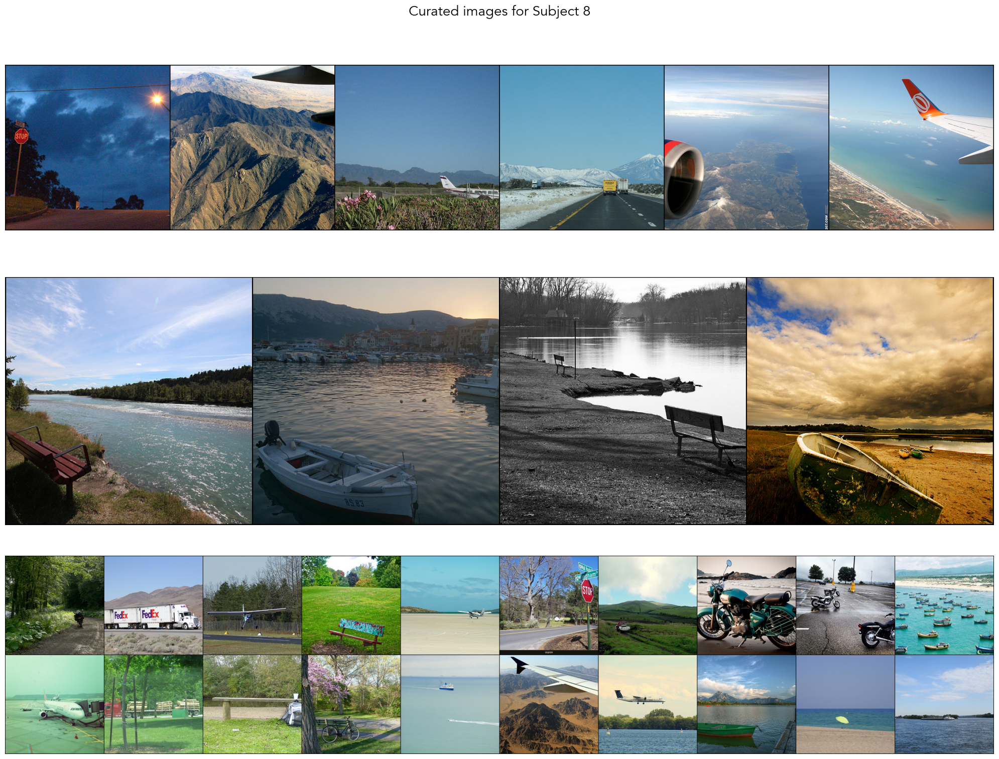

In [221]:
bag_type = 'scenes_humans'
stimuli = STIMULI
g1 = [1168, 11598, 17169, 18683, 19482, 19988]
g2 = [3147, 4024, 17756, 21602]
bag1_nsdids = bags[5][bag_type]['bag1']['nsdids']
g3 = [nsdid for nsdid in bag1_nsdids if nsdid not in g1+g2]
for subject in [8]:
    plt.figure(figsize=(20, 16))
    plt.subplot(3, 1, 1)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[g1]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(3, 1, 2)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[g2]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(3, 1, 3)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[g3]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

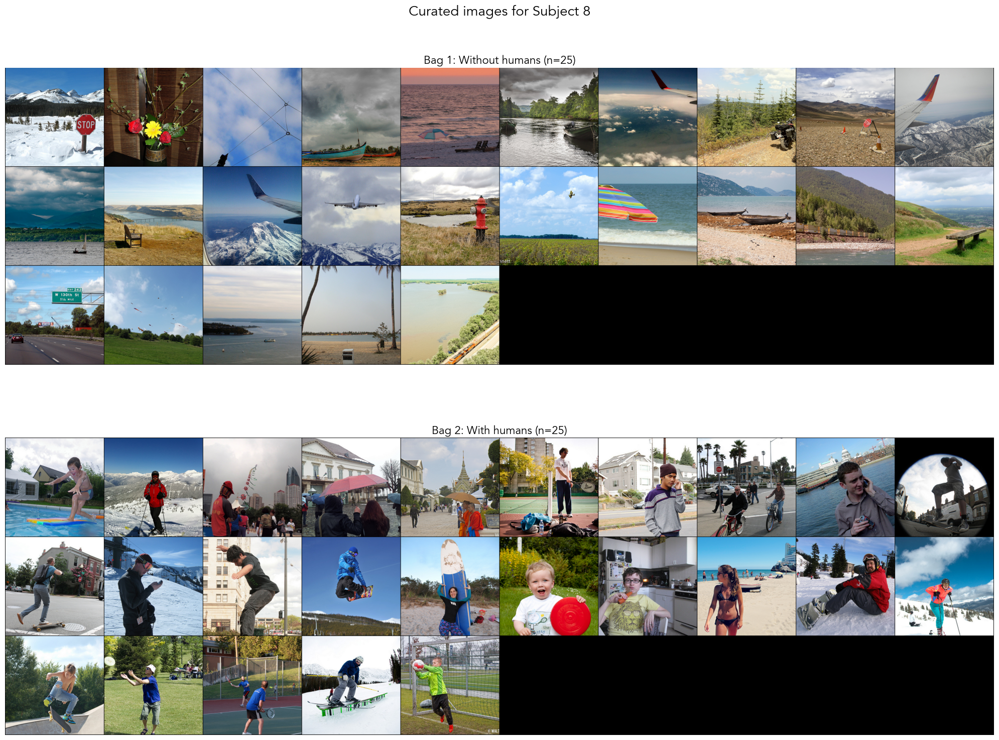

In [66]:
bag_type = 'scenes_humans'
stimuli = STIMULI
for subject in [8]:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(20, 16))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    plt.title(f"Bag 1: Without humans (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

# Dev

## EBA

Subject 2: 33 images in bag Localizer-like Poses, 28 images in bag Non-Localizer-like Poses
Subject 3: 30 images in bag Localizer-like Poses, 33 images in bag Non-Localizer-like Poses
Subject 4: 31 images in bag Localizer-like Poses, 30 images in bag Non-Localizer-like Poses
Subject 5: 30 images in bag Localizer-like Poses, 30 images in bag Non-Localizer-like Poses
Subject 6: 32 images in bag Localizer-like Poses, 27 images in bag Non-Localizer-like Poses
Subject 7: 31 images in bag Localizer-like Poses, 25 images in bag Non-Localizer-like Poses
Subject 8: 32 images in bag Localizer-like Poses, 32 images in bag Non-Localizer-like Poses


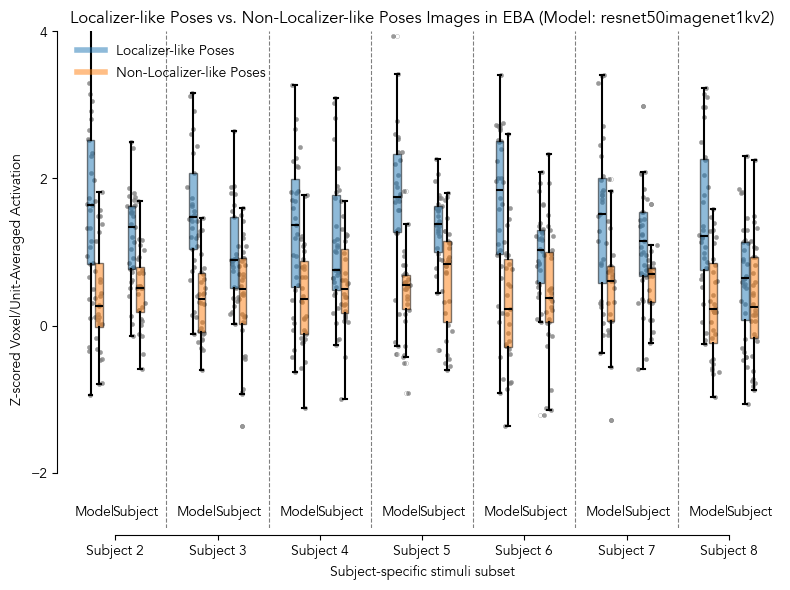

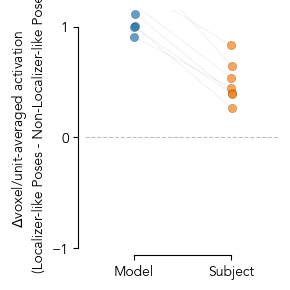

In [110]:
froi = 'EBA'
bag_type = 'bodies_localizerlike'
stimuli = STIMULI
subjects = [2, 3, 4, 5, 6, 7, 8]

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (md, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [md, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.15)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

In [ ]:
TOP_MODEL_NAMES = [
    'resnet50imagenet1kv2',
    'vitb16siglip2res224',
    'resnet50openaiclip',
    'convnexttinyimagenet1kv1',
    'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    'resnet101imagenet1kv1',
    'vitb14dinov2'
]
frois = ['FFA', 'PPA', 'EBA']

PPA, resnet101openaiclip model delta not normal (Shapiro p=0.0435)
PPA, vitb14dinov2 model delta not normal (Shapiro p=0.0479)


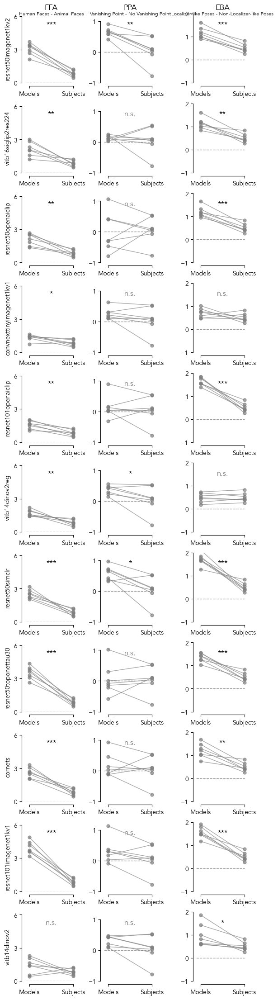

In [112]:
froi_bags = {
    'FFA': 'faces',
    'PPA': 'scenes_perspective',
    'EBA': 'bodies_localizerlike',
}

savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 2],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([ -1, 0, 1, 2]),
}
subjects = [2, 3, 4, 5, 6, 7, 8]

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

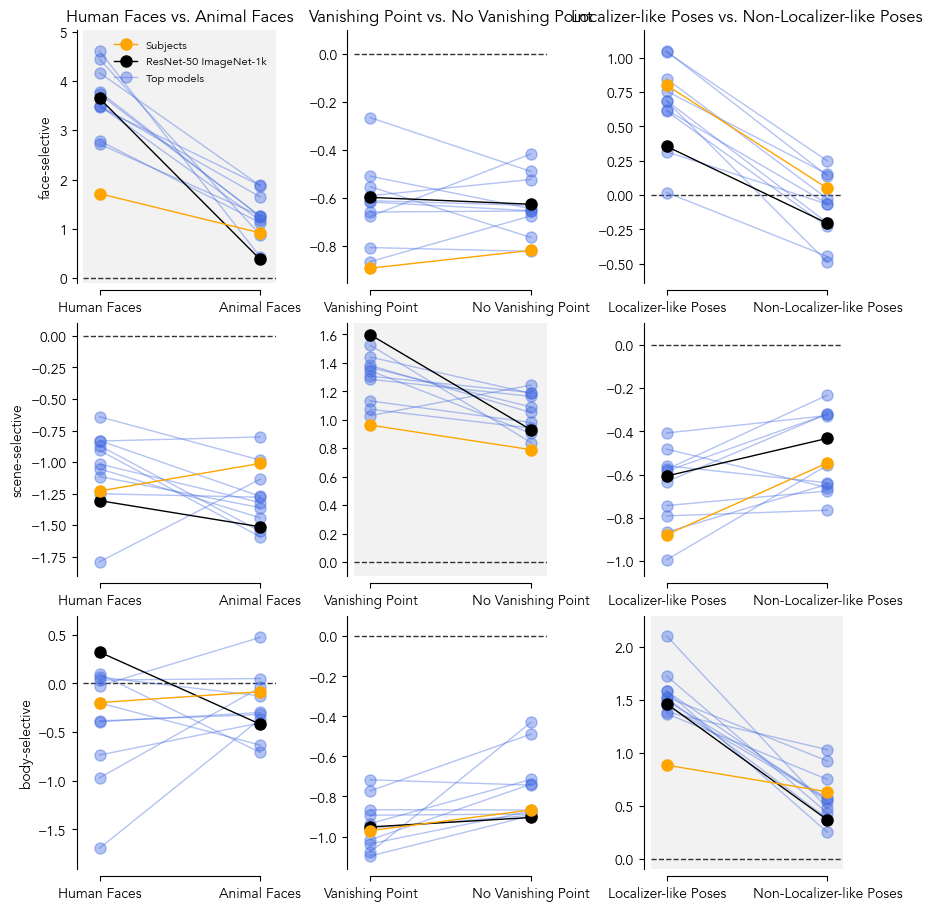

In [53]:
savefig = False

bag_types = ['faces', 'scenes_perspective', 'bodies_localizerlike']
frois = ['FFA', 'PPA', 'EBA']

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
rn50imgnet_color = 'k' # Black
othermodels_color = "royalblue"
subjects_color = 'orange'

subjects = range(2, 9) # range(2, 9)

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            model_pts = []
            for subject in subjects:
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.4,
                markersize=8,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Add median across subjects
        subject_pts = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        ax.plot([], [], '-o', color=othermodels_color, alpha=0.4, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

## FFA

29 images in bag Human Faces, 30 images in bag Animal Faces
loading annotations into memory...
Done (t=13.44s)
creating index...
index created!
loading annotations into memory...
Done (t=1.36s)
creating index...
index created!
loading annotations into memory...
Done (t=0.56s)
creating index...
index created!
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6714, RDMR: 0.3932
nsd ID subset mean, 
Mean Pearson r: 0.6416, Z-scored Pearson r: 0.6416


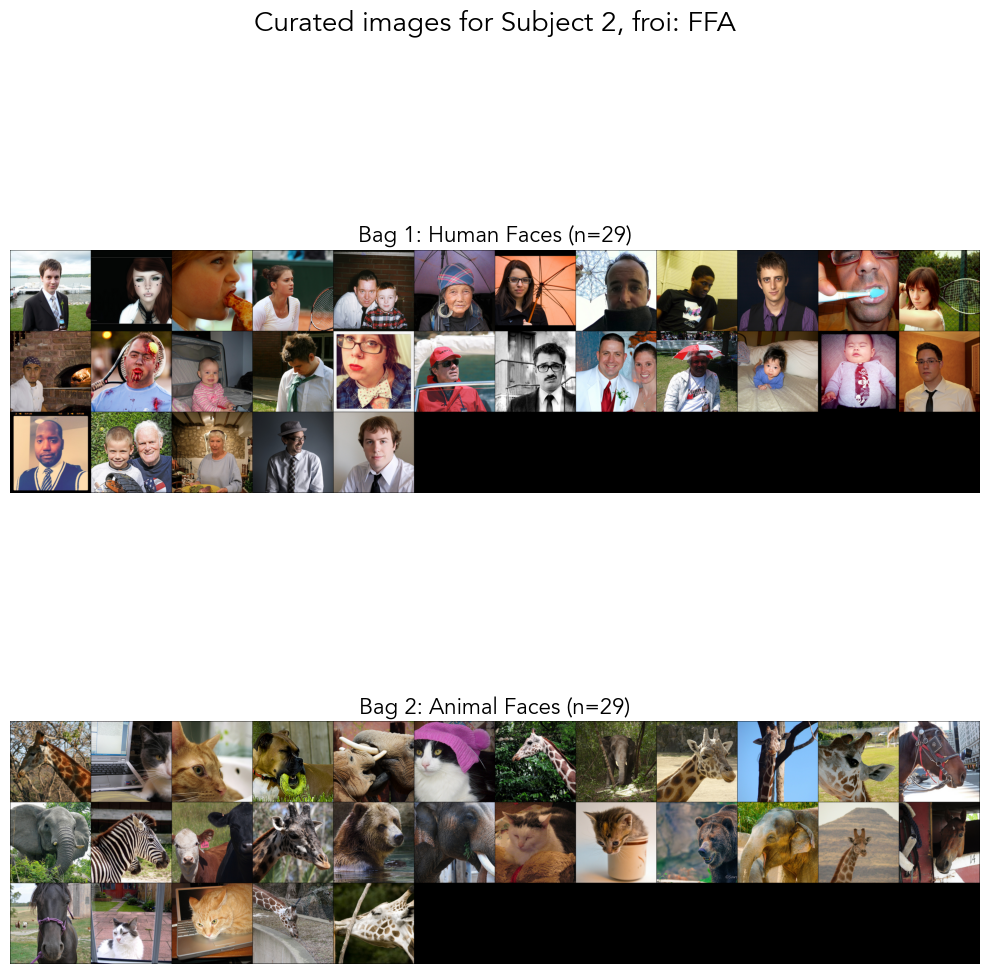

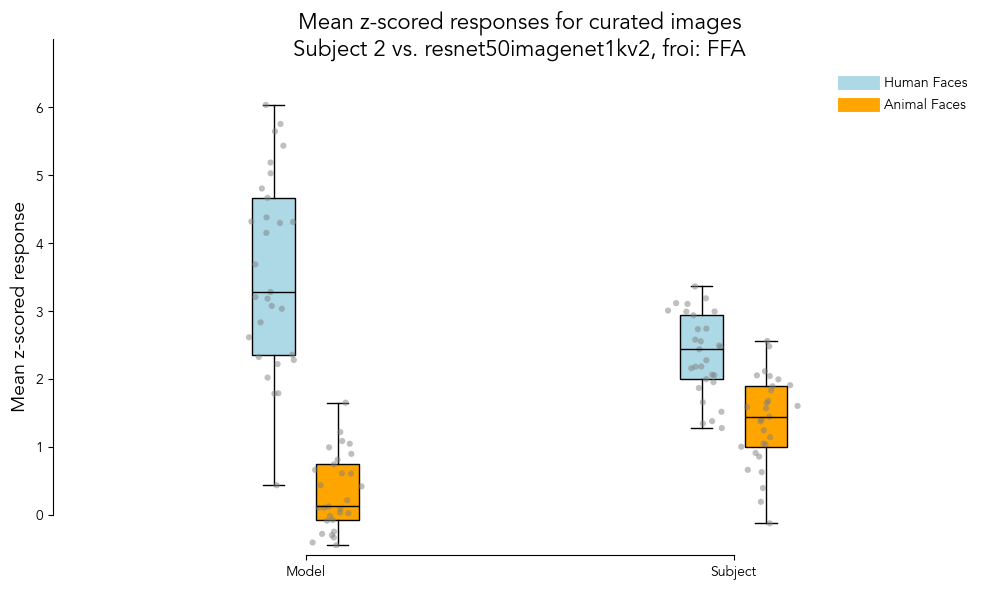

In [ ]:
subject = 2
froi = 'FFA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'
bag_type = 'faces'
bag1_info = bags[subject][bag_type]['bag1']
bag2_info = bags[subject][bag_type]['bag2']
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(10, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=8, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=8, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

# sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
#     df=sbj_froi_mdl_subset_resp_df,
#     images_np=stimuli_subset,
#     x_col='model_response',
#     y_col='subject_response',
#     color_col='response_diff',
#     info_cols=['labels', 'nsd_image_id'],
#     output_path=None,  # Change to a file path to save as HTML
#     title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
# )

# save_interactive_plot_as_html(
#     plot=sbj_froi_mdl_subset_scatter,
#     output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
# )


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(8, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

42 images in bag Liminal Scenes, 40 images in bag Typical Scenes
loading annotations into memory...
Done (t=26.61s)
creating index...
index created!
loading annotations into memory...
Done (t=1.81s)
creating index...
index created!
loading annotations into memory...
Done (t=0.84s)
creating index...
index created!
loading annotations into memory...
Done (t=0.16s)
creating index...
index created!
Full subset, 
Mean Pearson r: 0.6623, RDMR: 0.2498
nsd ID subset mean, 
Mean Pearson r: 0.3190, Z-scored Pearson r: 0.3190


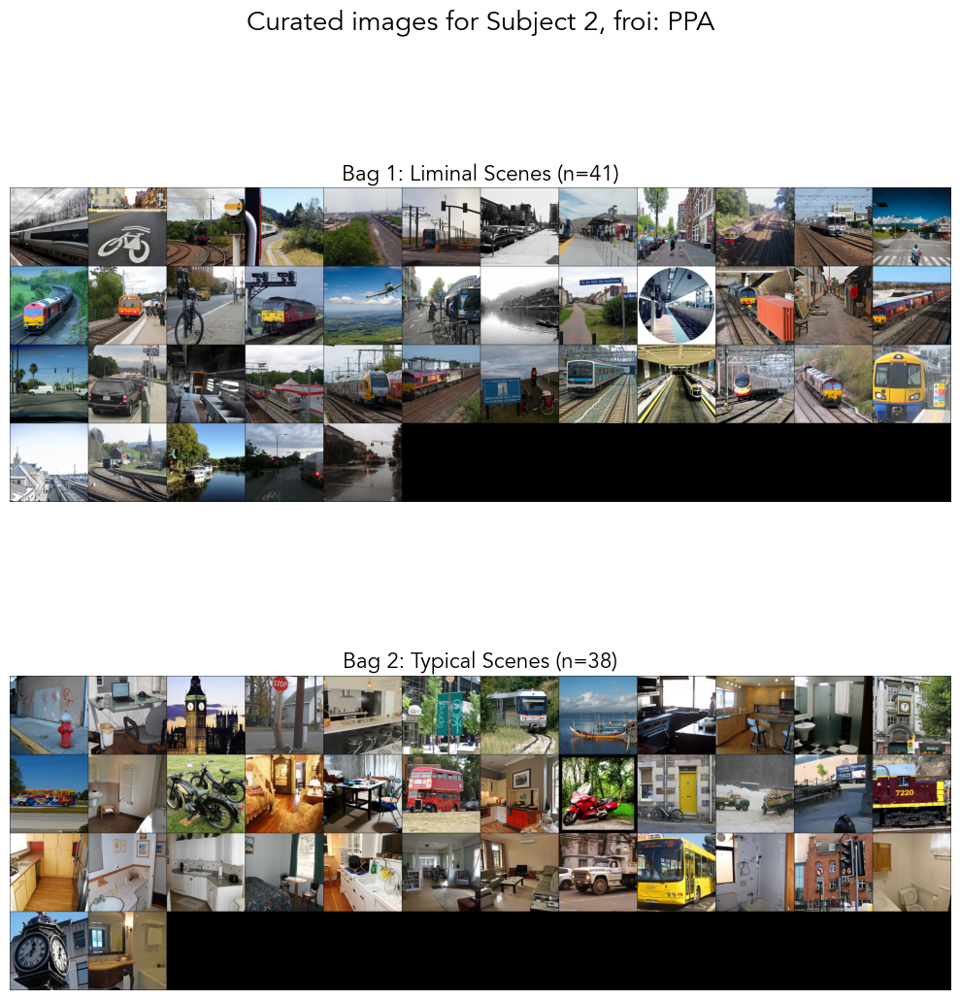

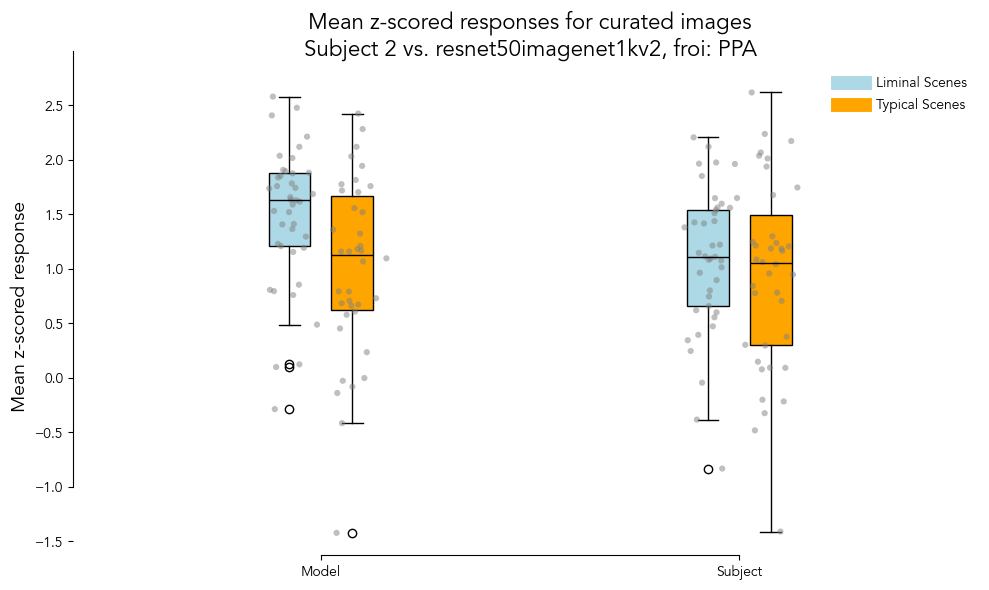

In [7]:
subject = 2
froi = 'PPA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'
bag_type = 'scenes'
bag1_info = bags[subject][bag_type]['bag1']
bag2_info = bags[subject][bag_type]['bag2']
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(10, 12))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=12, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

# sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
#     df=sbj_froi_mdl_subset_resp_df,
#     images_np=stimuli_subset,
#     x_col='model_response',
#     y_col='subject_response',
#     color_col='response_diff',
#     info_cols=['labels', 'nsd_image_id'],
#     output_path=None,  # Change to a file path to save as HTML
#     title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
# )

# save_interactive_plot_as_html(
#     plot=sbj_froi_mdl_subset_scatter,
#     output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
# )


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

In [ ]:
subject = 3
froi = 'PPA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'
bag_type = 'scenes'
bag1_info = bags[subject][bag_type]['bag1']
bag2_info = bags[subject][bag_type]['bag2']
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

sbj_froi_mdl_subset_resp_df, images_subset_df, stimuli_subset, sbj_froi_subset_data, mdl_froi_subset_data = get_data(
    subject=subject,
    froi=froi,
    subset=subset, # 515 for shared, None for subject-specific set
    model_name=model_name,
    nsdids=bag1_info['nsdids'] + bag2_info['nsdids']
)
# Get indices of the nsdids in each bag
bag1_indices = images_subset_df[images_subset_df['nsdId'].isin(bag1_info['nsdids'])].index.tolist()
bag2_indices = images_subset_df[images_subset_df['nsdId'].isin(bag2_info['nsdids'])].index.tolist()

plt.figure(figsize=(8, 6))
plt.subplot(2, 1, 1)
plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag1_indices]).permute(0, 3, 1, 2), nrow=8, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.subplot(2, 1, 2)
plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_indices)})", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli_subset[bag2_indices]).permute(0, 3, 1, 2), nrow=8, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
plt.tight_layout()
plt.show()
plt.close()

# sbj_froi_mdl_subset_scatter = plot_scatter_with_image_hover(
#     df=sbj_froi_mdl_subset_resp_df,
#     images_np=stimuli_subset,
#     x_col='model_response',
#     y_col='subject_response',
#     color_col='response_diff',
#     info_cols=['labels', 'nsd_image_id'],
#     output_path=None,  # Change to a file path to save as HTML
#     title=f"{froi.upper()}: Subject {subject} vs. {model_name}, {subset if subset else 'Subject-specific'} images",
# )

# save_interactive_plot_as_html(
#     plot=sbj_froi_mdl_subset_scatter,
#     output_path=f'{PLOTS_DIR}/curatedimages_s{subject}_{froi}_{model_name}_{subset if subset else 9000}_scatter.html'
# )


# Plot box plot of model person and animal respones, and subject person and animal responses
x_pos = [0.925, 1.075, 1.925, 2.075]
plot_data = {
    'Model ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["model_response"],
    'Model ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["model_response"],
    'Subject ' + bag1_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag1_indices]["subject_response"],
    'Subject ' + bag2_info['label']: sbj_froi_mdl_subset_resp_df.iloc[bag2_indices]["subject_response"],
}

plt.figure(figsize=(10, 6))
box = plt.boxplot(list(plot_data.values()), positions=x_pos, patch_artist=True, medianprops=dict(color='black'), widths=0.1)
colors = ['lightblue', 'orange']
for patch, color in zip(box['boxes'], colors*2):
    patch.set_facecolor(color)
# Legend, make empty plots with colors
for color, label in zip(colors, [bag1_info['label'], bag2_info['label']]):
    plt.plot([], [], color=color, label=label, linewidth=10)
plt.legend(loc='best', frameon=False)

# Add jittered scatter points
for i, (data, pos) in enumerate(zip(list(plot_data.values()), x_pos)):
    # Create jittered x-positions
    x_jitter = np.random.normal(pos, 0.03, size=len(data))
    plt.scatter(x_jitter, data, color='gray', alpha=0.5, s=20, edgecolor='none', zorder=2)

# Manual x-tick labels
plt.xticks([1, 2], ['Model', 'Subject'], rotation=15)

plt.ylabel('Mean z-scored response', fontsize=14)
plt.title(f'Mean z-scored responses for curated images\nSubject {subject} vs. {model_name}, froi: {froi}', fontsize=16)
ymin, ymax = np.concat(list(plot_data.values())).min(), np.concat(list(plot_data.values())).max()
plt.ylim(ymin*1.1, ymax*1.1)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(1, 2)
plt.gca().spines['left'].set_bounds(np.ceil(ymin), np.ceil(ymax))
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/subject_model_mean_zscored_response_boxplot_curatedfaces.png', dpi=300)
plt.show()
plt.close()

30 images in bag Liminal Scenes, 31 images in bag Typical Scenes


# PPA

## With/Without faces

In [38]:
TOP_MODEL_NAMES = [
    'resnet50imagenet1kv2',
    'vitb16siglip2res224',
    'resnet50openaiclip',
    'convnexttinyimagenet1kv1',
    'resnet101openaiclip',
    'vitb14dinov2reg',
    'resnet50simclr',
    'resnet50toponettau30',
    'cornets',
    'resnet101imagenet1kv1',
    'vitb14dinov2'
]
frois = ['FFA', 'PPA', 'EBA']
ppa_bag_type = 'scenes_humans'

bag_types = ['faces', ppa_bag_type, 'bodies_localizerlike']
froi_bags = {
    'FFA': 'faces',
    'PPA': ppa_bag_type,
    'EBA': 'bodies_localizerlike',
}
subjects = [6] # [2, 3, 4, 5, 6, 7, 8]
bag_type = ppa_bag_type

model_name = 'resnet50imagenet1kv2'
# model_name = 'vitb14dinov2reg'

Subject 6: 26 images in bag Non localiker-like Scenes, 26 images in bag With humans


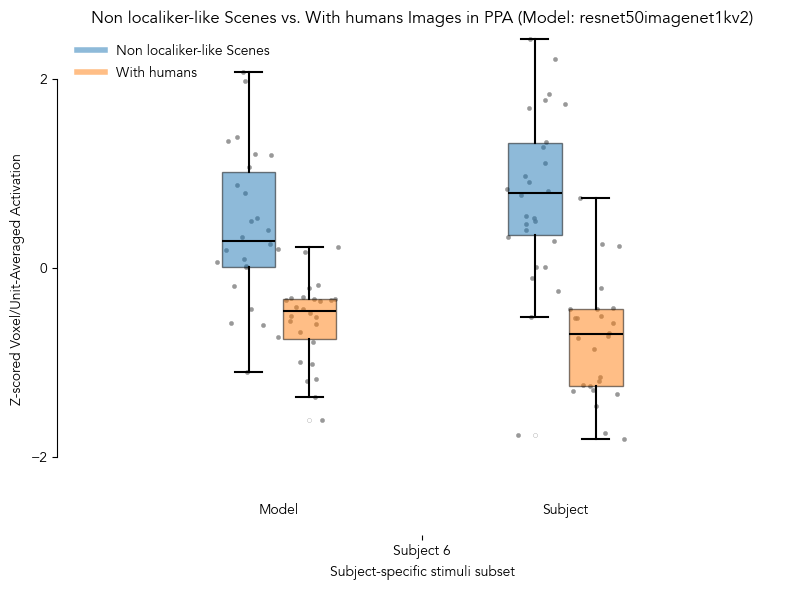

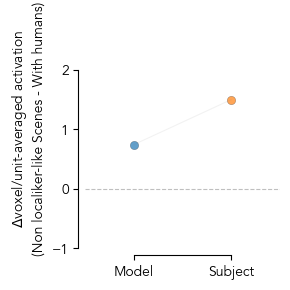

In [62]:
froi = 'PPA'
stimuli = STIMULI

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 2.5)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (md, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [md, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 2)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 2.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 3)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

,nsd_id,subject,froi,subject_response,resnet50imagenet1kv2_response
0,5450,6,PPA,0.232510,0.217626
1,7664,6,PPA,-0.432591,-0.560863
2,11507,6,PPA,-0.533891,-0.674341
3,17191,6,PPA,-1.295684,-1.371834
4,20873,6,PPA,-0.857916,-0.997381
5,28549,6,PPA,-0.214599,-0.507849
6,45852,6,PPA,-0.246465,-0.341033
7,56847,6,PPA,0.253036,0.167743
8,65968,6,PPA,0.740921,-0.183790
9,69930,6,PPA,-0.429940,-0.434787


,nsd_id,subject,froi,subject_response,resnet50imagenet1kv2_response
0,2526,6,PPA,-1.814212,-0.341447
1,3362,6,PPA,-1.306035,-0.522770
2,10473,6,PPA,-1.239524,-1.021656
3,20210,6,PPA,-0.692843,-0.478542
4,22633,6,PPA,-1.335117,-1.176731
5,23306,6,PPA,-0.533955,-0.335029
6,23943,6,PPA,-1.465062,-1.200086
7,24193,6,PPA,-0.738934,-0.346841
8,38334,6,PPA,-0.717646,-0.417208
9,40765,6,PPA,-1.255653,-0.599713


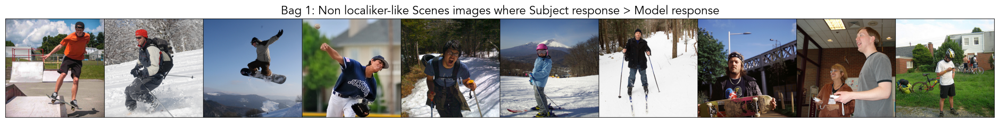

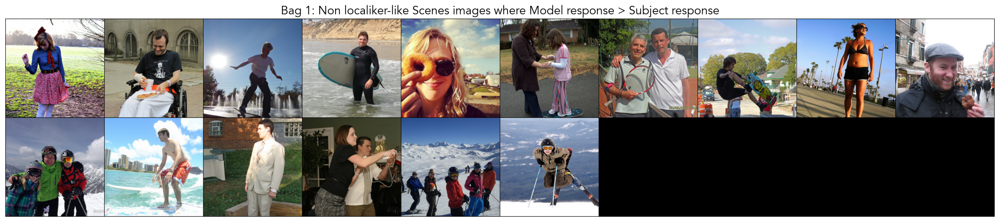

In [63]:
bag1_df = sbj_froi_mdl_subset_resp_df[
    sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
].copy()

col_mdl = f'{model_name}_response'

# Get images where subject response > model response
mask = bag1_df['subject_response'] > bag1_df[col_mdl]
bag1_gt_model = bag1_df.loc[
    mask, ['nsd_id', 'subject', 'froi', 'subject_response', col_mdl]
].sort_values('nsd_id', ascending=True)
# Display as CSV
display(bag1_gt_model.reset_index(drop=True))
# Get the nsd_ids and make a grid of the images
nsd_ids_gt_model = bag1_gt_model['nsd_id'].tolist()
nsd_ids_gt_model.sort()
plt.figure(figsize=(24, 12))
plt.title(f"Bag 1: {bag1_info['label']} images where Subject response > Model response", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli[nsd_ids_gt_model]).permute(0, 3, 1, 2), nrow=10, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')

# Get images where model response > subject response
mask = bag1_df[col_mdl] > bag1_df['subject_response']
bag1_gt_subject = bag1_df.loc[
    mask, ['nsd_id', 'subject', 'froi', 'subject_response', col_mdl]
].sort_values('nsd_id', ascending=True)
# Display as CSV
display(bag1_gt_subject.reset_index(drop=True))
# display(bag1_gt_subject.to_csv(index=False))
# Get the nsd_ids and make a grid of the images
nsd_ids_gt_subject = bag1_gt_subject['nsd_id'].tolist()
nsd_ids_gt_subject.sort()
plt.figure(figsize=(24, 12))
plt.title(f"Bag 1: {bag1_info['label']} images where Model response > Subject response", fontsize=16)
# Use torchvision utils to make a grid
grid = vutils.make_grid(torch.tensor(stimuli[nsd_ids_gt_subject]).permute(0, 3, 1, 2), nrow=10, padding=2)
plt.imshow(grid.permute(1, 2, 0))
plt.axis('off')
plt.show()

PPA, vitb16siglip2res224 model delta not normal (Shapiro p=0.0030)
PPA, vitb14dinov2reg model delta not normal (Shapiro p=0.0058)
FFA, resnet101imagenet1kv1 model delta not normal (Shapiro p=0.0497)


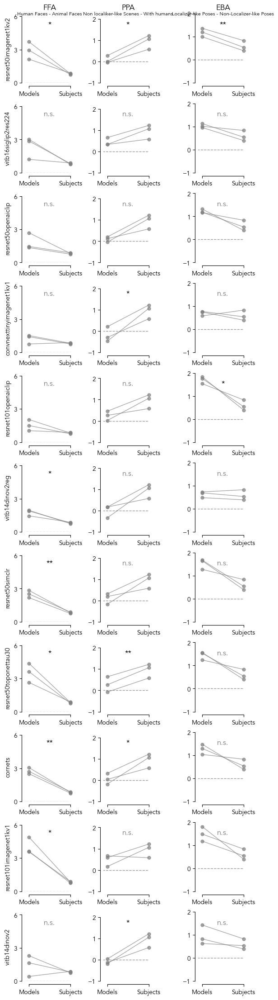

In [143]:
savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 2.25],
    'EBA': [-1, 2],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1, 2]),
    'EBA': np.array([ -1, 0, 1, 2]),
}

fig, axes = plt.subplots(len(TOP_MODEL_NAMES), len(frois), figsize=(2*len(frois), 2*len(TOP_MODEL_NAMES)), constrained_layout=True)
for midx, model_name in enumerate(TOP_MODEL_NAMES):
    subset = None # 515 for shared, None for subject-specific set
    # x_system_offset = 0.2
    # x_category_offset = 0.0425
    for fidx, froi in enumerate(frois):
        ax = axes[midx, fidx]
        bag_type = froi_bags[froi]
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        data_points = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            sbj_froi_mdl_subset_resp_df =resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi)
            ]
            subject_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ]['subject_response']
            subject_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ]['subject_response']
            model_bag1_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_nsdids)
            ][f'{model_name}_response']
            model_bag2_resp = sbj_froi_mdl_subset_resp_df[
                sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_nsdids)
            ][f'{model_name}_response']
            subject_delta = np.median(subject_bag1_resp) - np.median(subject_bag2_resp)
            model_delta = np.median(model_bag1_resp) - np.median(model_bag2_resp)
            data_points.append((model_delta, subject_delta))
        data_points = np.array(data_points)
        subject_delta_normt, subject_delta_normp = shapiro(data_points[:, 1])
        model_delta_normt, model_delta_normp = shapiro(data_points[:, 0])
        if subject_delta_normp < 0.05:
            print(f"{froi}, {model_name} subjects delta not normal (Shapiro p={subject_delta_normp:.4f})")
        if model_delta_normp < 0.05:
            print(f"{froi}, {model_name} model delta not normal (Shapiro p={model_delta_normp:.4f})")
        # y=0 line
        ax.plot([-1, 1], [0, 0], '--', color='gray', linewidth=1, alpha = 0.8)
        # Paired line plot
        for didx, dpt in enumerate(data_points):
            ax.plot(
                [0, 1],
                [dpt[0], dpt[1]],
                '-o',
                markersize=5,
                linewidth=1,
                color='gray',
                alpha=0.7,
                zorder=2
            )
        # Do a paired t-test and report the p-value
        t_stat, p_val = ttest_rel(data_points[:, 0], data_points[:, 1])
        # print(f"{froi}, {model_name}: t={t_stat:.2f}, p={p_val:.4f}")
        # Add significance asterisks
        if p_val < 0.001:
            sig_label = '***'
        elif p_val < 0.01:
            sig_label = '**'
        elif p_val < 0.05:
            sig_label = '*'
        else:
            sig_label = 'n.s.'
        ax.text(0.5, y_lims[1] - 0.1*(y_lims[1]-y_lims[0]), sig_label, ha='center', va='top', fontsize=12, color='black' if sig_label != 'n.s.' else 'gray')
        # ax.plot(data_points, '-o', color='gray', alpha=0.7, markersize=5, linewidth=1, zorder=2)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(['Models', 'Subjects'])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(y_lims)
        ax.set_yticks(y_ticks)
        # ax.set_xlabel(system + ' Response (z-scored)')
        # ax.set_title('Model' if system == model_name else 'Subject')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(model_name if fidx == 0 else "")
        type_label = f'{bags[2][froi_bags[froi]]["bag1"]["label"]} - {bags[2][froi_bags[froi]]["bag2"]["label"]}'
        # ax.set_title(f'{froi}\n' + fr'\small({type_label})' if midx == 0 else "")
        if midx == 0:
            # ax.set_title(f"{froi}\n{type_label}", fontsize=12)
            # then shrink only the second line
            ax.title.set_text(f"{froi}")
            ax.title.set_fontsize(12)  # main size
            # manually shrink the second line
            # ax.set_title(f"{type_label}", fontsize=12, loc="center")
            # ax.text(0.5, 1.02, froi, transform=ax.transAxes,
            #         ha='center', va='bottom', fontsize=12)
            ax.text(0.5, 0.96, type_label, transform=ax.transAxes,
                    ha='center', va='bottom', fontsize=8)
        else:
            ax.set_title("")
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

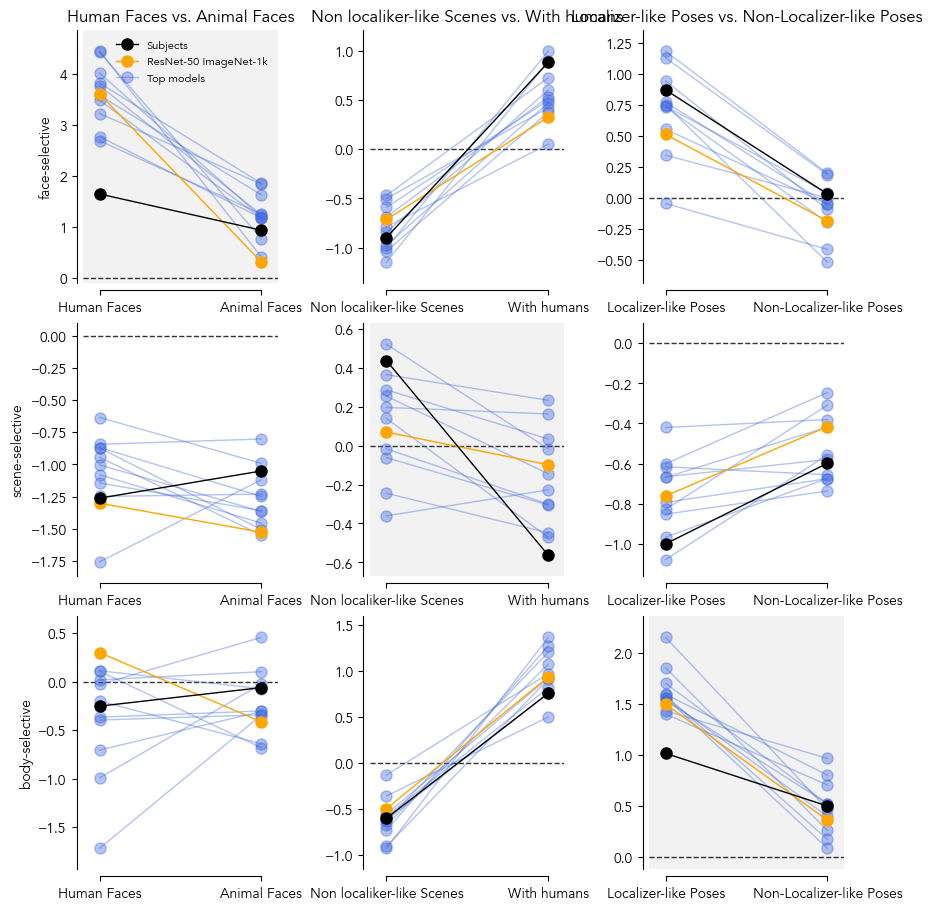

In [23]:
savefig = False

froi_lims = {
    'FFA': [0, 6.25],
    'PPA': [-1, 1.25],
    'EBA': [-1, 3.25],
}
froi_ticks = {
    'FFA': np.array([0, 3, 6]),
    'PPA': np.array([-1, 0, 1]),
    'EBA': np.array([-1, 0, 1, 2, 3]),
}
froi_labels = {
    'FFA': 'face-selective',
    'PPA': 'scene-selective',
    'EBA': 'body-selective',
}
rn50imgnet_color = 'orange' # Black
othermodels_color = "royalblue"
subjects_color = 'k'

fig, axes = plt.subplots(len(frois), len(bag_types), figsize=(3*len(bag_types), 3*len(frois)), constrained_layout=True)
for bidx, bag_type in enumerate(bag_types):
    bag1_label = bags[2][bag_type]['bag1']['label']
    bag2_label = bags[2][bag_type]['bag2']['label']
    for fidx, froi in enumerate(frois):
        ax = axes[fidx, bidx]
        if fidx == bidx: # Highlight the diagonal
            ax.set_facecolor((0.5, 0.5, 0.5, 0.1))
        ax_pts = []
        y_lims = froi_lims[froi]
        y_ticks = froi_ticks[froi]
        # y=0 line
        ax.axhline(y=0, color='k', linestyle='--', linewidth=1, alpha=0.8)
        for model_name in reversed(TOP_MODEL_NAMES):
            model_pts = []
            for subject in subjects:
                bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
                bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
                model_responses_bag1_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag1_nsdids))
                ][f'{model_name}_response'])
                model_responses_bag2_median = np.median(resp_df[
                    (resp_df['subject'] == subject) &
                    (resp_df['froi'] == froi) &
                    (resp_df['nsd_id'].isin(bag2_nsdids))
                ][f'{model_name}_response'])
                model_pts.append((model_responses_bag1_median, model_responses_bag2_median))
            model_pts = np.array(model_pts)
            model_pts_medians = np.median(model_pts, axis=0)
            ax_pts += model_pts_medians.tolist()
            ax.plot(
                [0, 1],
                [model_pts_medians[0], model_pts_medians[1]],
                '-o',
                color=rn50imgnet_color if model_name == 'resnet50imagenet1kv2' else othermodels_color,
                alpha=1 if model_name == 'resnet50imagenet1kv2' else 0.4,
                markersize=8,
                linewidth=1,
                # zorder=5,
                # label=model_name if model_name == 'resnet50imagenet1kv2' else ("other models" if bidx == 0 and fidx == 0 else ""),
            )
        # Add median across subjects
        subject_pts = []
        for subject in subjects:
            bag1_nsdids = bags[subject][bag_type]['bag1']['nsdids']
            bag2_nsdids = bags[subject][bag_type]['bag2']['nsdids']
            subject_responses_bag1_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag1_nsdids))
            ]['subject_response'])
            subject_responses_bag2_median = np.median(resp_df[
                (resp_df['subject'] == subject) &
                (resp_df['froi'] == froi) &
                (resp_df['nsd_id'].isin(bag2_nsdids))
            ]['subject_response'])
            subject_pts.append((subject_responses_bag1_median, subject_responses_bag2_median))
        subject_pts = np.array(subject_pts)
        subject_pts_medians = np.median(subject_pts, axis=0)
        ax_pts += subject_pts_medians.tolist()
        ax.plot(
            [0, 1],
            [subject_pts_medians[0], subject_pts_medians[1]],
            '-o',
            color=subjects_color,
            alpha=1,
            markersize=8,
            linewidth=1,
            # zorder=6,
            label='Subjects' if bidx == 0 and fidx == 0 else "",
        )
        # Plot properties
        ax_pts = np.array(ax_pts)
        ax_min = np.min([ax_pts.min() - 0.1*(ax_pts.max() - ax_pts.min()), -0.1])
        ax_max = np.max([ax_pts.max() + 0.1*(ax_pts.max() - ax_pts.min()), 0.1])
        # Set legend labels manually
        ax.plot([], [], '-o', color=rn50imgnet_color, alpha=1, markersize=8, linewidth=1, label='ResNet-50 ImageNet-1k')
        ax.plot([], [], '-o', color=othermodels_color, alpha=0.4, markersize=8, linewidth=1, label='Top models')
        ax.set_xticks([0, 1])
        ax.set_xticklabels([bag1_label, bag2_label])
        ax.set_xlim([-0.1, 1.1])
        ax.set_ylim(ax_min, ax_max)
        # ax.set_yticks(y_ticks)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_position(('outward', 5))
        ax.spines['bottom'].set_position(('outward', 5))
        # ax.spines['left'].set_bounds(y_ticks.min(), y_ticks.max())
        ax.spines['bottom'].set_bounds(0, 1)
        ax.set_ylabel(froi_labels[froi] if bidx == 0 else "")
        type_label = f'{bag1_label} vs. {bag2_label}'
        if fidx == 0:
            ax.set_title(f"{type_label}", fontsize=12)
        else:
            ax.set_title("")
        if bidx == 0 and fidx == 0:
            ax.legend(frameon=False, fontsize=8, loc='upper right')
if savefig:
    raise NotImplementedError
    # plt.savefig(f'{PLOTS_DIR}/supfig_lineplot_allmodelsfrois.pdf', dpi=300, bbox_inches='tight')
else:
    plt.show()
plt.close()

## Scenes

In [3]:
subject = 1
froi = 'PPA'
subset = None # 515 for shared, None for subject-specific set
model_name = 'resnet50imagenet1kv2'
bag_type = 'scenes'
bag1_info = bags[subject][bag_type]['bag1']
bag2_info = bags[subject][bag_type]['bag2']
print(f"{len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")

stimuli = STIMULI
sbj_froi_mdl_subset_resp_df =resp_df[
    (resp_df['subject'] == subject) &
    (resp_df['froi'] == froi)
]

KeyError: 'scenes'

In [ ]:
bag_type = 'scenes_perspective'
stimuli = STIMULI
# TODO: 1
for subject in [5, 6, 7, 8]:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(20, 12))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

## Liminal

In [24]:
froi = 'PPA'
bag_type = 'scenes'
stimuli = STIMULI
subjects = SUBJECTS.copy()

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (md, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [md, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.15)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

KeyError: 'scenes'

## Perspective

Subject 2: 32 images in bag Vanishing Point, 26 images in bag No Vanishing Point
Subject 3: 21 images in bag Vanishing Point, 26 images in bag No Vanishing Point
Subject 4: 30 images in bag Vanishing Point, 27 images in bag No Vanishing Point
Subject 5: 27 images in bag Vanishing Point, 25 images in bag No Vanishing Point
Subject 6: 34 images in bag Vanishing Point, 32 images in bag No Vanishing Point
Subject 7: 21 images in bag Vanishing Point, 21 images in bag No Vanishing Point
Subject 8: 21 images in bag Vanishing Point, 17 images in bag No Vanishing Point


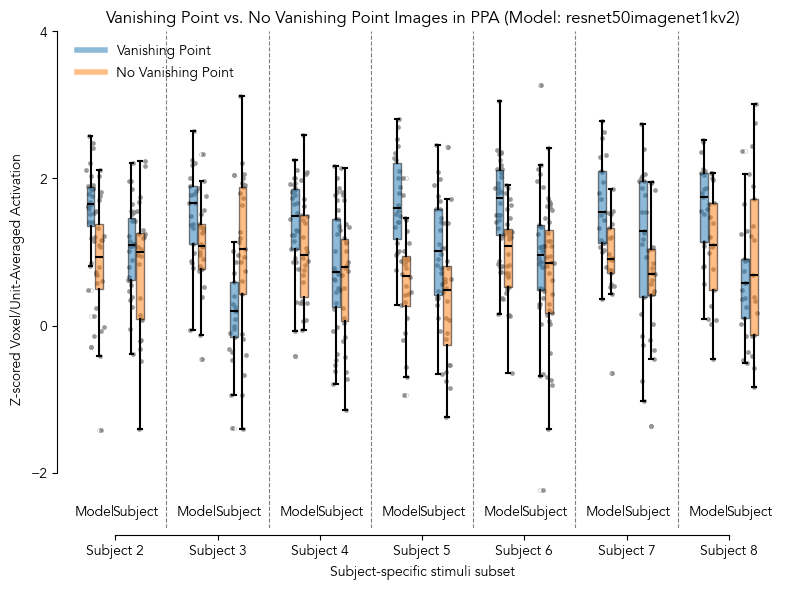

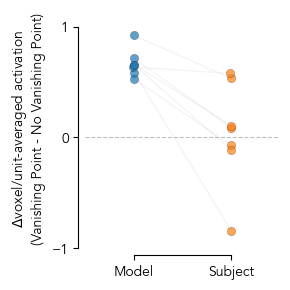

In [23]:
froi = 'PPA'
bag_type = 'scenes_perspective'
stimuli = STIMULI
subjects = SUBJECTS.copy()

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
subjects_eval = list(range(2, 9))  # Only subjects 2-8 have perspective bags
for sidx, subject in enumerate(subjects_eval):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects_eval)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects_eval)), [f'Subject {s}' for s in subjects_eval])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects_eval)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects_eval)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.15)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

## Faces

Subject 2: 31 images in bag Human Faces, 30 images in bag Animal Faces


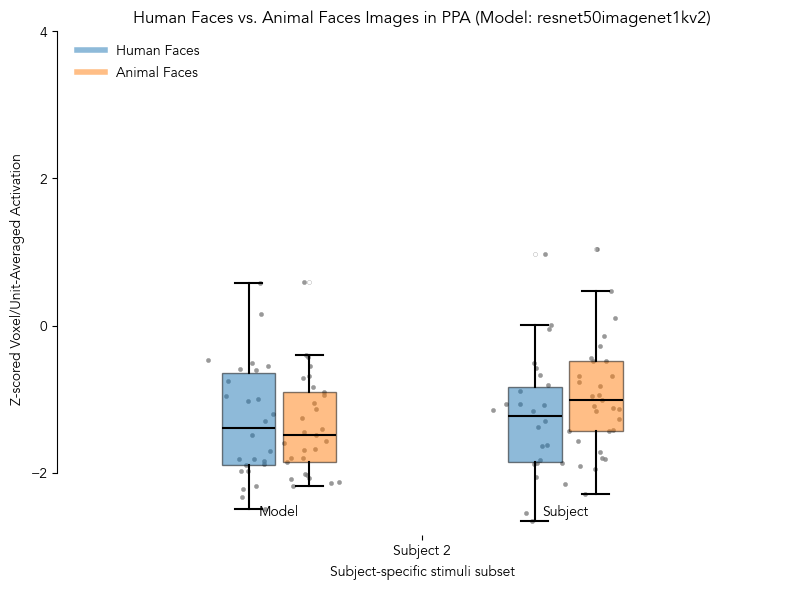

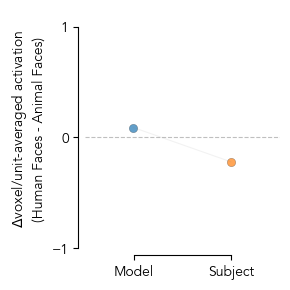

In [26]:
froi = 'PPA'
bag_type = 'faces'
stimuli = STIMULI
subjects = SUBJECTS.copy()

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
subjects_eval = list(range(2, 3))  # Only subjects 2-8 have perspective bags
for sidx, subject in enumerate(subjects_eval):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects_eval)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects_eval)), [f'Subject {s}' for s in subjects_eval])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects_eval)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects_eval)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.15)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

## Localizer-like

Subject 2: 34 images in bag Localizer-like Scenes, 28 images in bag Non-localizer-like Scenes


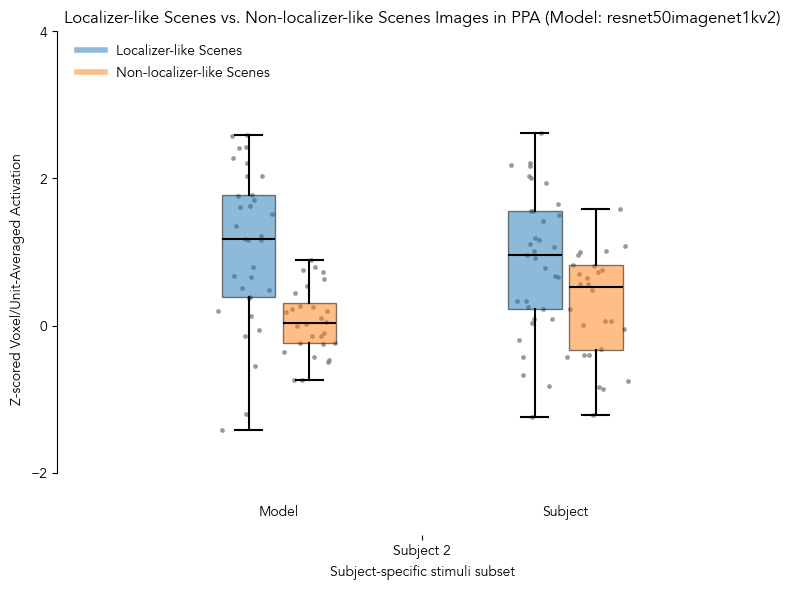

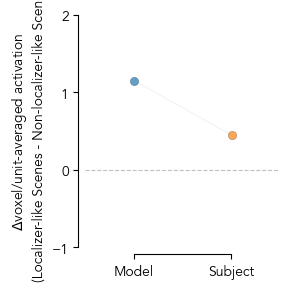

In [50]:
froi = 'PPA'
bag_type = 'scenes_localizerlike'
stimuli = STIMULI
subjects = SUBJECTS.copy()

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
subjects_eval = list(range(2, 3))  # Only subjects 2-8 have perspective bags
for sidx, subject in enumerate(subjects_eval):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects_eval)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects_eval)), [f'Subject {s}' for s in subjects_eval])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects_eval)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects_eval)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (md, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [md, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 2)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 2.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 2)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

Subject 2: 34 images in bag Localizer-like Scenes, 28 images in bag Non-localizer-like Scenes


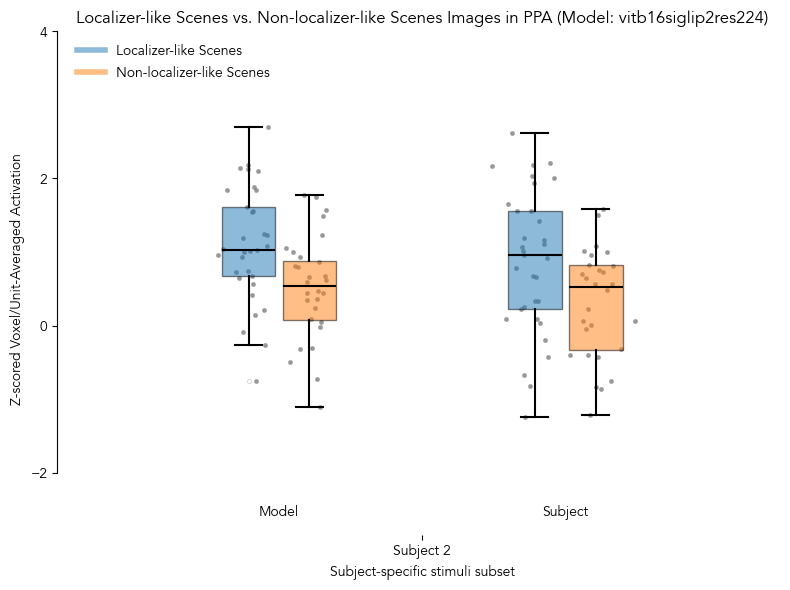

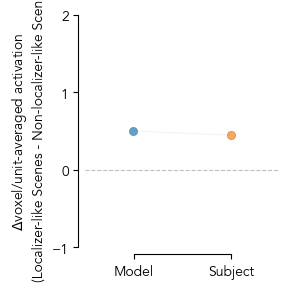

In [51]:
froi = 'PPA'
bag_type = 'scenes_localizerlike'
stimuli = STIMULI
subjects = SUBJECTS.copy()

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'vitb16siglip2res224'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.65
bags_median_deltas = []
subjects_eval = list(range(2, 3))  # Only subjects 2-8 have perspective bags
for sidx, subject in enumerate(subjects_eval):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects_eval)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects_eval)), [f'Subject {s}' for s in subjects_eval])
plt.yticks([-2, 0, 2, 4])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects_eval)-1)
plt.gca().spines['left'].set_bounds(-2, 4)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 4)
plt.xlim(-0.5, len(subjects_eval)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (md, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [md, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 2)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 2.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 2)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# FFA

Subject 1: 15 images in bag Human Faces, 27 images in bag Animal Faces
Subject 2: 29 images in bag Human Faces, 30 images in bag Animal Faces
Subject 3: 27 images in bag Human Faces, 26 images in bag Animal Faces
Subject 4: 44 images in bag Human Faces, 36 images in bag Animal Faces
Subject 5: 20 images in bag Human Faces, 27 images in bag Animal Faces
Subject 6: 34 images in bag Human Faces, 30 images in bag Animal Faces
Subject 7: 36 images in bag Human Faces, 39 images in bag Animal Faces
Subject 8: 30 images in bag Human Faces, 26 images in bag Animal Faces


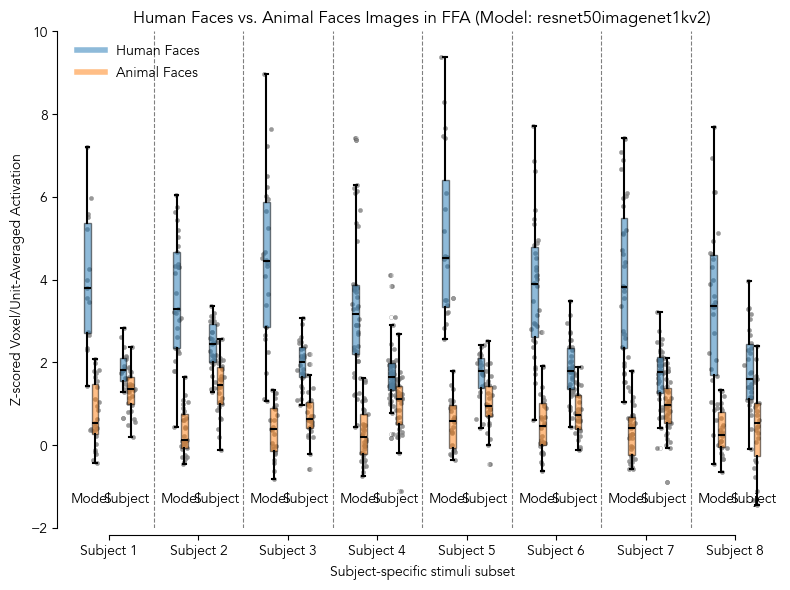

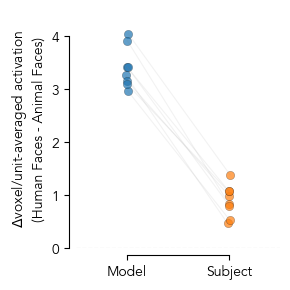

In [11]:
froi = 'FFA'
bag_type = 'faces'
stimuli = STIMULI
subjects = SUBJECTS.copy()

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6))
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -1.5
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 10)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2, 10)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(0, 4)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(0, 4.01, 1))
# ax.legend(frameon=False)
plt.ylim(0, 4.5)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

In [ ]:
froi = 'FFA'
bag_type = 'faces'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(1)  # Subject 1 is the training subject

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -1.5
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 10)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2, 10)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(0, 4)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(0, 4.01, 1))
# ax.legend(frameon=False)
plt.ylim(0, 4.5)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# EBA

## Human vs. Animal Faces

In [ ]:
froi = 'EBA'
bag_type = 'faces'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(1)  # Subject 1 is the train subject

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.8
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 2)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

In [28]:
bags_median_deltas

[(0.20303911000000002, 0.1920265),
 (1.08669405, -0.1590837045),
 (0.7023310100000001, -0.28631400475),
 (0.6852290249999999, -0.3054756045),
 (0.94495418, 0.10014562100000002),
 (0.76619945, -0.3040447),
 (0.426141105, 0.5407223)]

## Human vs. Animal Bodies

In [ ]:
froi = 'EBA'
bag_type = 'bodies'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(5) # Subject 5 has no bodies images curated

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -1.25
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-1, 3)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.yticks([-1, 0, 1, 2, 3])
plt.ylim(-1.25, 3.25)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-1, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-1, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

## Human Faces vs. Bodies

In [ ]:
froi = 'EBA'
bag_type = 'human_faces_bodies'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(5) # Subject 5 has no bodies images curated

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -1.25
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-1, 3)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.yticks([-1, 0, 1, 2, 3])
plt.ylim(-1.25, 3.25)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-2, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-2, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

## Animal Faces vs. Bodies

In [ ]:
froi = 'EBA'
bag_type = 'animal_faces_bodies'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(5) # Subject 5 has no bodies images curated

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6))
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=12, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -1.25
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-1, 3)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.yticks([-1, 0, 1, 2, 3])
plt.ylim(-1.25, 3.25)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-1, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-2, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-2, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

## Human Faces vs. Animal Bodies

In [ ]:
froi = 'EBA'
bag_type = 'human_faces_animal_bodies'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(1)  # Subject 1 is the train subject

for subject in subjects:
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    plt.figure(figsize=(10, 6), dpi=300)
    plt.subplot(2, 1, 1)
    plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.subplot(2, 1, 2)
    plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
    # Use torchvision utils to make a grid
    grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
    plt.tight_layout()
    plots_dir_tmp = f'{PLOTS_DIR}/tmp'
    os.makedirs(plots_dir_tmp, exist_ok=True)
    # plt.savefig(f'{plots_dir_tmp}/curated_images_subject{subject}_{froi}_{bag_type}.png', dpi=300)
    plt.show()
    plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.2
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 3)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-2, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-2, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-2, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()

Subject 2: 24 images in bag Human Faces, 30 images in bag Animal Bodies
Subject 3: 21 images in bag Human Faces, 25 images in bag Animal Bodies
Subject 4: 35 images in bag Human Faces, 36 images in bag Animal Bodies
Subject 5: 31 images in bag Human Faces, 25 images in bag Animal Bodies
Subject 6: 28 images in bag Human Faces, 30 images in bag Animal Bodies
Subject 7: 20 images in bag Human Faces, 43 images in bag Animal Bodies
Subject 8: 18 images in bag Human Faces, 28 images in bag Animal Bodies


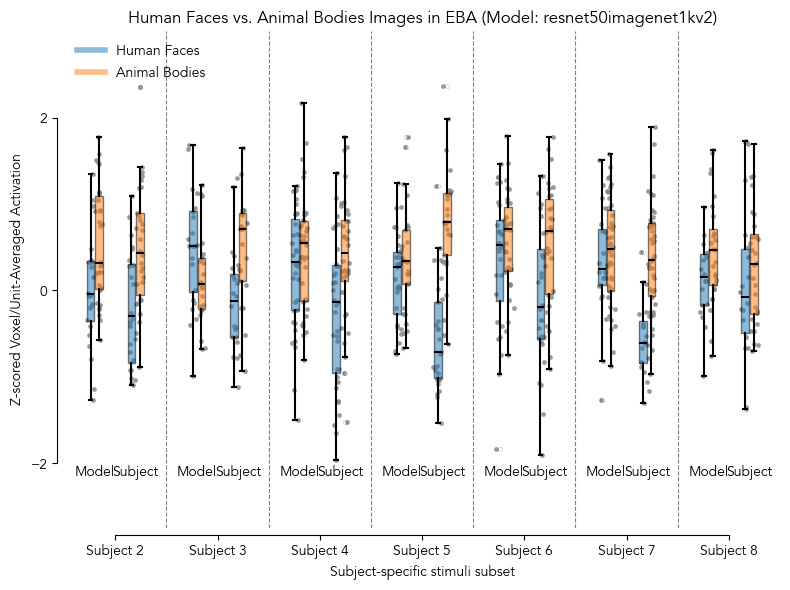

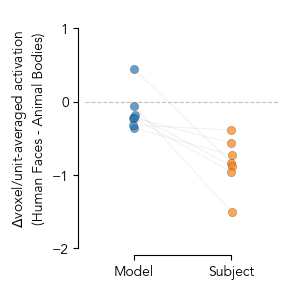

In [35]:
froi = 'EBA'
bag_type = 'human_faces_animal_bodies'
stimuli = STIMULI
subjects = SUBJECTS.copy()
subjects.remove(1)  # Subject 1 is the train subject

# for subject in subjects:
#     bag1_info = bags[subject][bag_type]['bag1']
#     bag2_info = bags[subject][bag_type]['bag2']
#     plt.figure(figsize=(10, 6), dpi=300)
#     plt.subplot(2, 1, 1)
#     plt.title(f"Bag 1: {bag1_info['label']} (n={len(bag1_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag1_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.subplot(2, 1, 2)
#     plt.title(f"Bag 2: {bag2_info['label']} (n={len(bag2_info['nsdids'])})", fontsize=16)
#     # Use torchvision utils to make a grid
#     grid = vutils.make_grid(torch.tensor(stimuli[bag2_info['nsdids']]).permute(0, 3, 1, 2), nrow=10, padding=2)
#     plt.imshow(grid.permute(1, 2, 0))
#     plt.axis('off')
#     plt.suptitle(f'Curated images for Subject {subject}, froi: {froi}', fontsize=20)
#     plt.tight_layout()
#     plots_dir_tmp = f'{PLOTS_DIR}/tmp'
#     os.makedirs(plots_dir_tmp, exist_ok=True)
#     # plt.savefig(f'{plots_dir_tmp}/curated_images_subject{subject}_{froi}_{bag_type}.png', dpi=300)
#     plt.show()
#     plt.close()

model_name = 'resnet50imagenet1kv2'
subset = None # 515 for shared, None for subject-specific set
x_system_offset = 0.2
x_category_offset = 0.0425
plt.figure(figsize=(8, 6))
text_y = -2.2
bags_median_deltas = []
for sidx, subject in enumerate(subjects):
    sbj_froi_mdl_subset_resp_df =resp_df[
        (resp_df['subject'] == subject) &
        (resp_df['froi'] == froi)
    ]
    bag1_info = bags[subject][bag_type]['bag1']
    bag2_info = bags[subject][bag_type]['bag2']
    print(f"Subject {subject}: {len(bag1_info['nsdids'])} images in bag {bag1_info['label']}, {len(bag2_info['nsdids'])} images in bag {bag2_info['label']}")
    model_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ][f'{model_name}_response']
    model_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ][f'{model_name}_response']
    subject_bag1_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag1_info['nsdids'])
    ]['subject_response']
    subject_bag2_points = sbj_froi_mdl_subset_resp_df[
        sbj_froi_mdl_subset_resp_df['nsd_id'].isin(bag2_info['nsdids'])
    ]['subject_response']
    bags_median_deltas.append((
        model_bag1_points.median() - model_bag2_points.median(),
        subject_bag1_points.median() - subject_bag2_points.median(),
    ))
    boxes_x = [
        sidx - x_system_offset - x_category_offset, sidx - x_system_offset + x_category_offset,
        sidx + x_system_offset - x_category_offset, sidx + x_system_offset + x_category_offset
    ] # model bag1, model bag2, subject bag1, subject bag2
    boxes_data = [model_bag1_points, model_bag2_points, subject_bag1_points, subject_bag2_points]
    box_colors = ['#1f77b4', '#ff7f0e', '#1f77b4', '#ff7f0e']
    box_labels = ['Model ' + bag1_info['label'], 'Model ' + bag2_info['label'], 'Subject ' + bag1_info['label'], 'Subject ' + bag2_info['label']]
    box_positions = ['left', 'right', 'left', 'right']
    for bx, bd, bc, bl, bp in zip(boxes_x, boxes_data, box_colors, box_labels, box_positions):
        box = plt.boxplot(
            bd, positions=[bx], widths=0.075, patch_artist=True, boxprops=dict(facecolor=bc, alpha=0.5),
            flierprops=dict(marker='o', color=bc, alpha=0.5, markersize=3, markeredgecolor='k', markeredgewidth=0.2),
            medianprops=dict(color='k', linewidth=1.5),
            whiskerprops=dict(color='k', linewidth=1.5),
            capprops=dict(color='k', linewidth=1.5),
            showfliers=True, zorder=2
        )
        # Add individual points
        y = bd
        x = np.random.normal(bx, 0.02, size=len(y))
        plt.scatter(x, y, s=10, alpha=0.8, color='gray', label=bl if sidx == 0 else "", edgecolor=None, linewidth=0.2)
    # Add subject and Model label
    plt.text(sidx + x_system_offset, text_y, f'Subject', ha='center', va='bottom', fontsize=10)
    plt.text(sidx - x_system_offset, text_y, f'Model', ha='center', va='bottom', fontsize=10)
# Plot dashed line at y=0
# plt.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5, zorder=1)
# Plot dashed vertical lines at the middle between each subject
for sidx in range(len(subjects)-1):
    plt.axvline(x=sidx + 0.5, color='k', linestyle='--', linewidth=0.8, alpha=0.5)
plt.xticks(range(len(subjects)), [f'Subject {s}' for s in subjects])
plt.yticks([-2, 0, 2, 4, 6, 8, 10])
plt.xlabel('Subject-specific stimuli subset')
plt.ylabel('Z-scored Voxel/Unit-Averaged Activation')
plt.title(f"{bag1_info['label']} vs. {bag2_info['label']} Images in {froi} (Model: {model_name})")
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['left'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_position(('outward', 5))
plt.gca().spines['bottom'].set_bounds(0, len(subjects)-1)
plt.gca().spines['left'].set_bounds(-2, 2)
# Custom legend
custom_lines = [
    plt.Line2D([0], [0], color='#1f77b4', alpha=0.5, lw=4, label=bag1_info['label']),
    plt.Line2D([0], [0], color='#ff7f0e', alpha=0.5, lw=4, label=bag2_info['label'])
]
plt.legend(handles=custom_lines, loc='upper left', frameon=False)
# plt.ylim(plt.ylim()[0], plt.ylim()[1] + 0.3)
plt.ylim(-2.75, 3)
plt.xlim(-0.5, len(subjects)-0.5)
# plt.grid(axis='y')
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_distributions_{froi}_person_vs_animal.png', dpi=300)
plt.show()

# Plot person_animal_median_deltas as a scatter plot with median marked across subjects and models, and pair the points
fig, ax = plt.subplots(figsize=(3, 3))
model_deltas, subject_deltas = zip(*bags_median_deltas)
x_jitter = np.random.normal(0, 0.005, size=len(model_deltas))
x_models = [1]*len(model_deltas)+x_jitter
x_subjects = [2]*len(subject_deltas)+x_jitter
ax.scatter(x_models, model_deltas, color='#1f77b4', alpha=0.7, label='Model', edgecolor='k', linewidth=0.2)
ax.scatter(x_subjects, subject_deltas, color='#ff7f0e', alpha=0.7, label='Subject', edgecolor='k', linewidth=0.2)
# Pair the points
for idx, (pd, sd) in enumerate(zip(model_deltas, subject_deltas)):
    ax.plot(
        [x_models[idx], x_subjects[idx]],
        [pd, sd], color='gray', alpha=0.1, linewidth=0.8
    )
ax.set_xticks([1, 2], ['Model', 'Subject'])
ax.set_ylabel(r'$\Delta$voxel/unit-averaged activation' + f'\n({bag1_info['label']} - {bag2_info['label']})')
# ax.set_title(f'Median Person vs. Animal Activation Differences in {froi} (Model: {model_name})')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_position(('outward', 5))
ax.spines['bottom'].set_position(('outward', 5))
ax.spines['bottom'].set_bounds(1, 2)
ax.spines['left'].set_bounds(-2, 1)
ax.axhline(y=0, color='gray', linestyle='--', linewidth=0.8, alpha=0.5)
plt.yticks(np.arange(-2, 1.01, 1))
# ax.legend(frameon=False)
plt.ylim(-2, 1.25)
plt.xlim(0.5, 2.5)
plt.tight_layout()
# plt.savefig(f'{PLOTS_DIR}/activation_median_deltas_{froi}_person_vs_animal.png', dpi=300)
plt.show()